# ITSG Growth ARR Forecast — Foundation v5

Weekly ARR forecast for **ITSG Growth bookings** (net-new, `amount_towards_plan`), from raw Salesforce
OLI data to Delta output tables, using five models — Prophet, MSTL, ETS (Holt-Winters), DHR-ARIMA, and a
Global LightGBM quantile model — combined into an Adaptive Ensemble with market-level reconciliation, a
27-week production forward forecast, a Monte Carlo quarterly-distribution step, and a monitoring baseline.

ITSG is a small, noisy series (~$0.35M average weekly ARR — roughly a third of UCC), so this notebook is
deliberately conservative: every accuracy claim comes from data the models never trained on or tuned
against, and the quarterly Monte Carlo distributions matter at least as much as the point forecasts.

**Key methodology changes vs the prior version (V4), all flagged again at the step where they live:**

1. **Clean evaluation splits.** Three-way temporal split: CV region → 13-week validation slice (tuning
   only) → untouched holdout from `2026-01-05`. V4 ran 8 CV folds across the whole series, so folds 7-8
   trained on data inside the holdout; here the fold count is computed so no fold touches it, and asserts
   enforce the boundary.
2. **LightGBM panel rebuilt on a complete SFDC spine.** V4 built the LGB panel on `forecast_prophet`'s
   rows (~84% market-week coverage), leaving holes in the target and gappy lag features — the root cause
   of its ~120% holdout WAPE. v2 builds a full week × market grid, takes the target from SFDC ATP, and
   left-joins `forecast_prophet` as features only.
3. **Removed the holdout-derived global scaling.** V4 multiplied every production forecast by a 0.831
   "calibration" factor estimated from holdout errors — an adjustment applied in production but absent
   from every reported metric. v2 has no such transform: evaluation measures exactly what production does.
4. **Ensemble weights from clean CV, not the holdout.** Inverse mean CV WAPE (all folds pre-holdout).
   V4's fallback weighted by holdout WAPE, contaminating the ensemble's own holdout numbers.
5. **Tuned, not hand-picked, hyperparameters.** The training-window length (78 vs 104 vs all weeks),
   Prophet's changepoint prior, ETS seasonality, MSTL periods, DHR Fourier order, and LGB depth/rate are
   all selected on the validation slice — one place, never the holdout. V4 hardcoded a 78-week window and
   applied it inconsistently (benchmarks rolling, LGB expanding).
6. **Consistent, comparable metrics.** All models are evaluated at the weekly *total* level with the same
   metric code (V4 scored LGB at market level, producing meaningless 400,000% MAPEs on near-zero slices);
   quarter definitions come from `to_period('Q')` everywhere (V4 had three conflicting "Q1 actual" values).
7. **Deterministic LightGBM** (`deterministic=true`, single thread) so identical data reproduces identical
   results; recursive prediction keeps ≥60 weeks of history so long lags don't silently zero out (V4 kept
   26, starving `y_lag26/52` at prediction time only).
8. **Data-driven LGB promotion gate.** V4 excluded LGB from the ensemble via a hardcoded comment. v2
   tests the rebuilt LGB on the validation slice and includes it only if it's within 1.25x the best
   benchmark's validation WAPE — the decision is printed, not hand-maintained.
9. **All summaries generated from live DataFrames** — no hand-typed metrics anywhere (V4's summary
   contradicted its own cell outputs). Non-negativity is enforced inside every model's predict path.

**Additional improvements (v2.1 session):**

10. **Continuous quarter-end proximity features** (`qe_proximity`, `qe_proximity_sq`) added to
    LightGBM's feature set — a 0→1 ramp for weeks 9-13 that models the nonlinear surge shape better
    than the binary `quarter_end_flag`. Expected: -1 to -2 WAPE pts.
11. **Data freshness check** (Step 1B) — flags the last closed week if it falls below 15% of the
    trailing 8-week average, preventing stale/incomplete data from entering production.

**Status:** freshly rewritten, not yet executed. Outputs are intentionally empty; run top-to-bottom on
Databricks after the Step 0 kernel restart.

### Step 0 — Install forecasting dependencies *(unchanged)*

`statsforecast` (MSTL/AutoETS/AutoARIMA), `prophet`, `statsmodels` (Holt-Winters ETS), `holidays`,
`lightgbm`, `scipy`, `shap`. Databricks restarts Python after this cell — re-run everything from the top.

In [0]:
# STEP 0: INSTALL FORECASTING DEPENDENCIES
# ─────────────────────────────────────────────────────────────────────────────
# PURPOSE: Install all Python libraries not pre-loaded in the Databricks runtime.
# Run this cell ONCE per new cluster session.  After it completes, Databricks
# automatically restarts the Python kernel — you must re-run ALL subsequent
# cells from the top before any model results will be valid.
#
# Package breakdown:
#   statsforecast  — Fast vectorised time-series models: MSTL v2, AutoETS,
#                    AutoARIMA.  Used in Steps 4 and 5.
#   prophet        — Facebook/Meta Prophet: trend + seasonality + holiday
#                    decomposition model.  Used in Step 4.
#   statsmodels    — ExponentialSmoothing (Holt-Winters) and ARIMA utilities
#                    used inside the DHR-ARIMA helper (Step 5).
#   holidays       — Public-holiday calendars for US/UK/DE/IN/BR.
#                    Used to build the `us_holiday_binary` external regressor.
#   lightgbm       — Gradient-boosted trees for the Global LGB Quantile model
#                    (Step 6) and Adaptive Ensemble weighting.
#   scipy          — Required by statsforecast's internal optimisers.
#   shap           — SHAP TreeExplainer for LightGBM feature importance.
# ─────────────────────────────────────────────────────────────────────────────

%pip install statsforecast prophet statsmodels holidays lightgbm scipy shap

Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


### Step 1 — Load ITSG forecast base data **(CHANGED — complete spine, target/feature separation, consistency diagnostic)**

Business scope preserved from V4: closed-won SFDC opportunity line items, `product_group = 'ITSG'`,
`purchase_type_rollup = 'Growth'`, channels excluding Care / Sales Other, `close_date >= 2023-01-01`,
target = weekly Monday-bucketed sum of `amount_towards_plan` (V4's "ATP fix" — kept). Changes:

- **Calendar spine.** Weekly and week × market series are built on a complete Monday grid so
  zero-booking weeks exist as $0 rows instead of silently missing (critical for lag/rolling features on a
  series this sparse — some ITSG market-weeks genuinely book nothing).
- **`forecast_prophet` is features-only.** Its `Actuals` column is loaded as `fp_actuals_reference` and
  never used as a target or feature; the target always comes from SFDC ATP. A diagnostic prints how far
  the two series diverge (V4 found a 0.67x mismatch — that comparison is now a permanent, visible check).
- All pipeline-style features (`all_created_arr`, headcount, activity aggregates) come from
  `forecast_prophet`, which is an all-outcome source — so there is no won-only survivorship problem in the
  feature set. `datagroup.uc_forecast.actuals` (RSG-IT mapping) remains a feature-only input.
- The total-level feature frame for DHR is assembled on the spine with per-column forward-fill, so feature
  gaps in `forecast_prophet` don't punch holes in the regressor matrix.

In [0]:
# STEP 1: LOAD ITSG FORECAST BASE DATA
# =============================================================================
# PURPOSE: Build the weekly modeling universe from raw SFDC data.  Produces:
#   * weekly_itsg            — total ITSG Growth ARR time series (forecast target)
#   * weekly_itsg_by_market  — per-market panel for LightGBM global training
#   * feature_source_total_hist — total-level feature frame for DHR-ARIMA
#
# SOURCE TABLE: datagroup.datalake_transform.cds_sfdc_opp_products_latest
#   One row per SFDC Opportunity Line Item.  Filters:
#   product_group='ITSG', purchase_type_rollup='Growth', is_won, is_closed,
#   sales_channel NOT IN ('Care','Sales Other'), close_date >= 2023-01-01
#
# KEY COLUMNS:
#   ds (week_start)           — Monday bucket of close_date (target grain)
#   sales_market              — geographic segment: NA, EMEA, APAC, LATAM, Unknown
#   arr (amount_towards_plan) — THE TARGET: weekly sum = y
#   deal_count                — number of closed OLIs per week (volume signal)
#
# FEATURE SOURCE: datagroup_mdl.mdl_sales_analytics.forecast_prophet
#   READ ONLY — supplies headcount, pipeline, deal size, cycle time features.
#   Its Actuals column is loaded as fp_actuals_reference for DIAGNOSTIC ONLY.
#
# CHANGED vs V4:
#   * Complete Monday calendar spine for total and week x market series
#     (zero weeks exist as $0 rows; V4 dropped them).
#   * forecast_prophet.Actuals loaded as fp_actuals_reference — DIAGNOSTIC
#     ONLY, never a target or feature. Target is always SFDC ATP.
#   * Total-level feature frame built on the spine with ffill (no gaps).
# UNCHANGED: business filters, ATP target definition, table names,
#   RSG-IT mapping for authoritative actuals.
# =============================================================================

import numpy as np
import pandas as pd

BASE_TABLE = 'datagroup.datalake_transform.cds_sfdc_opp_products_latest'
FEATURE_TABLE = 'datagroup_mdl.mdl_sales_analytics.forecast_prophet'          # READ ONLY
AUTHORITATIVE_ACTUALS_TABLE = 'datagroup.uc_forecast.actuals'                 # READ ONLY
PRODUCT_SCOPE = 'ITSG'
AUTHORITATIVE_ACTUALS_PRODUCT = 'RSG-IT'
START_DATE = '2023-01-01'
FIRST_FULL_MONDAY = pd.Timestamp('2023-01-02')
CURRENT_WEEK_START = pd.Timestamp.today().normalize() - pd.to_timedelta(pd.Timestamp.today().weekday(), unit='D')
LAST_CLOSED_WEEK = CURRENT_WEEK_START - pd.Timedelta(weeks=1)
MARKET_MAP = {'AUS/ROW': 'APAC', 'INDIA': 'APAC', 'UNKNOWN': 'Unknown', '': 'Unknown'}
GLOBAL_MARKETS = ['APAC', 'EMEA', 'LATAM', 'NA', 'Unknown']


def normalize_market(series: pd.Series) -> pd.Series:
    out = series.fillna('Unknown').astype(str).str.strip().str.upper()
    out = out.replace(MARKET_MAP)
    return out.replace({'UNKNOWN': 'Unknown'}).fillna('Unknown')


# --- Target query: closed-won ITSG Growth OLIs, ATP metric (unchanged scope) --
itsg_raw = spark.sql(f"""
SELECT
    salesforce_opportunity_line_item_id,
    opportunity_product_id,
    account_id_18_char,
    owner_id,
    CAST(close_date AS DATE) AS close_date,
    DATE_TRUNC('WEEK', CAST(close_date AS DATE)) AS ds,
    UPPER(COALESCE(sales_market, 'Unknown')) AS sales_market,
    UPPER(COALESCE(product_group, 'Unknown')) AS product_group,
    purchase_type_rollup,
    sales_channel,
    CAST(amount_towards_plan AS DOUBLE) AS arr
FROM {BASE_TABLE}
WHERE is_won = 'True'
  AND is_closed = 'True'
  AND close_date >= DATE '{START_DATE}'
  AND close_date <= CURRENT_DATE()
  AND UPPER(COALESCE(product_group, '')) = '{PRODUCT_SCOPE}'
  AND purchase_type_rollup = 'Growth'
  AND COALESCE(sales_channel, '') NOT IN ('Care', 'Sales Other')
ORDER BY ds
""").toPandas()

itsg_raw['ds'] = pd.to_datetime(itsg_raw['ds'])
itsg_raw['arr'] = pd.to_numeric(itsg_raw['arr'], errors='coerce').fillna(0.0)
itsg_raw['sales_market'] = normalize_market(itsg_raw['sales_market'])
itsg_raw = itsg_raw[itsg_raw['ds'] >= FIRST_FULL_MONDAY].copy()
assert len(itsg_raw) > 0, 'Target query returned no rows — check filters.'

# --- Complete Monday spine (CHANGED: V4 had no spine; zero weeks vanished) ----
calendar = pd.DataFrame({'ds': pd.date_range(FIRST_FULL_MONDAY, LAST_CLOSED_WEEK, freq='W-MON')})
ALL_MARKETS = sorted(set(itsg_raw['sales_market'].unique()) | set(GLOBAL_MARKETS))
market_calendar = (
    calendar.assign(_k=1)
    .merge(pd.DataFrame({'sales_market': ALL_MARKETS}).assign(_k=1), on='_k')
    .drop(columns='_k')
)

weekly_itsg = (
    calendar.merge(itsg_raw.groupby('ds', as_index=False).agg(y=('arr', 'sum'), deal_count=('arr', 'count')), on='ds', how='left')
    .sort_values('ds').reset_index(drop=True)
)
weekly_itsg[['y', 'deal_count']] = weekly_itsg[['y', 'deal_count']].fillna(0.0)
assert len(weekly_itsg) == len(calendar), 'weekly_itsg must have one row per spine week.'
assert weekly_itsg['y'].sum() > 0

weekly_itsg_by_market = (
    market_calendar.merge(
        itsg_raw.groupby(['ds', 'sales_market'], as_index=False).agg(y=('arr', 'sum'), deal_count=('arr', 'count')),
        on=['ds', 'sales_market'], how='left',
    )
    .sort_values(['ds', 'sales_market']).reset_index(drop=True)
)
weekly_itsg_by_market[['y', 'deal_count']] = weekly_itsg_by_market[['y', 'deal_count']].fillna(0.0)
# Market series must reconcile exactly to the total series
_mkt_total = weekly_itsg_by_market.groupby('ds')['y'].sum().sort_index()
assert np.allclose(_mkt_total.values, weekly_itsg.sort_values('ds')['y'].values, atol=1.0)

# --- Feature source: forecast_prophet (FEATURES ONLY — Actuals is diagnostic) -
feature_source_all = spark.sql(f"""
SELECT
    CAST(ds AS DATE) AS ds,
    UPPER(COALESCE(sales_market, 'Unknown')) AS sales_market,
    CAST(Actuals AS DOUBLE) AS fp_actuals_reference,
    CAST(Forecast_Median AS DOUBLE) AS prophet_ml,
    CAST(all_created_arr AS DOUBLE) AS all_created_arr,
    CAST(headcount AS DOUBLE) AS headcount,
    CAST(avg_deal_size AS DOUBLE) AS avg_deal_size,
    CAST(avg_sales_cycle AS DOUBLE) AS avg_sales_cycle,
    CAST(avg_push_counter AS DOUBLE) AS avg_push_counter,
    CAST(avg_dials AS DOUBLE) AS avg_dials,
    CAST(avg_touches AS DOUBLE) AS avg_touches,
    CAST(avg_opportunity_age AS DOUBLE) AS avg_opportunity_age,
    CAST(total_partner_pipeline AS DOUBLE) AS total_partner_pipeline,
    CAST(magna_carta_actuals AS DOUBLE) AS magna_carta_actuals,
    CAST(miradore_plan AS DOUBLE) AS miradore_plan
FROM {FEATURE_TABLE}
WHERE UPPER(COALESCE(product, '')) = '{PRODUCT_SCOPE}'
  AND ds >= DATE '{START_DATE}'
ORDER BY ds, sales_market
""").toPandas()
feature_source_all['ds'] = pd.to_datetime(feature_source_all['ds'])
feature_source_all['sales_market'] = normalize_market(feature_source_all['sales_market'])
FP_FEATURE_COLS = ['prophet_ml', 'all_created_arr', 'headcount', 'avg_deal_size', 'avg_sales_cycle',
                   'avg_push_counter', 'avg_dials', 'avg_touches', 'avg_opportunity_age',
                   'total_partner_pipeline', 'magna_carta_actuals', 'miradore_plan']
# Collapse duplicate (ds, market) rows defensively
feature_source_all = feature_source_all.groupby(['ds', 'sales_market'], as_index=False).agg(
    {c: 'sum' for c in ['fp_actuals_reference'] + FP_FEATURE_COLS}
)
OBSERVED_END = weekly_itsg['ds'].max()

# --- Target-source consistency diagnostic (visible, permanent) ----------------
fp_total = (
    feature_source_all[feature_source_all['ds'] <= OBSERVED_END]
    .groupby('ds', as_index=False)['fp_actuals_reference'].sum()
)
target_consistency = weekly_itsg[['ds', 'y']].rename(columns={'y': 'sfdc_atp'}).merge(fp_total, on='ds', how='left')
target_consistency['diff_dollars'] = target_consistency['sfdc_atp'] - target_consistency['fp_actuals_reference']
_overlap = target_consistency.dropna(subset=['fp_actuals_reference'])
print('Target consistency (SFDC ATP vs forecast_prophet.Actuals — the latter is NEVER used as target):')
if len(_overlap):
    print(f"  Overlapping weeks: {len(_overlap):,} | SFDC total ${_overlap['sfdc_atp'].sum()/1e6:.2f}M "
          f"vs fp ${_overlap['fp_actuals_reference'].sum()/1e6:.2f}M "
          f"(ratio {_overlap['fp_actuals_reference'].sum()/max(_overlap['sfdc_atp'].sum(),1):.2f}x)")
    print(f"  Mean abs weekly diff: ${_overlap['diff_dollars'].abs().mean():,.0f}")
# Feature-table spine coverage (the V4 LGB failure mode — now just a diagnostic)
_fp_pairs = set(map(tuple, feature_source_all[feature_source_all['ds'] <= OBSERVED_END][['ds', 'sales_market']].values.tolist()))
_spine_pairs = set(map(tuple, market_calendar[['ds', 'sales_market']].values.tolist()))
print(f"  forecast_prophet market-week coverage vs full spine: {100.0 * len(_fp_pairs & _spine_pairs) / len(_spine_pairs):.1f}% "
      f"(v2 builds the LGB panel on the FULL spine, so gaps become ffilled features, not missing targets)")

# --- Total-level feature frame on the spine (for DHR, Step 5) -----------------
feature_source_total_hist = (
    calendar.merge(
        feature_source_all[feature_source_all['ds'] <= OBSERVED_END]
        .groupby('ds', as_index=False)
        .agg(
            prophet_ml=('prophet_ml', 'sum'),
            all_created_arr=('all_created_arr', 'sum'),
            headcount=('headcount', 'sum'),
            avg_deal_size=('avg_deal_size', 'mean'),
            avg_sales_cycle=('avg_sales_cycle', 'mean'),
            avg_push_counter=('avg_push_counter', 'mean'),
            avg_dials=('avg_dials', 'mean'),
            avg_touches=('avg_touches', 'mean'),
            avg_opportunity_age=('avg_opportunity_age', 'mean'),
            total_partner_pipeline=('total_partner_pipeline', 'sum'),
            magna_carta_actuals=('magna_carta_actuals', 'sum'),
            miradore_plan=('miradore_plan', 'sum'),
        ),
        on='ds', how='left',
    )
    .merge(weekly_itsg[['ds', 'y', 'deal_count']], on='ds', how='left')
    .sort_values('ds').reset_index(drop=True)
)
for col in FP_FEATURE_COLS:
    feature_source_total_hist[col] = pd.to_numeric(feature_source_total_hist[col], errors='coerce').ffill().fillna(0.0)
assert len(feature_source_total_hist) == len(calendar)

itsg_overview = pd.DataFrame([
    {'metric': 'weekly_rows', 'value': str(len(weekly_itsg))},
    {'metric': 'market_rows', 'value': str(len(weekly_itsg_by_market))},
    {'metric': 'history_start', 'value': str(weekly_itsg['ds'].min().date())},
    {'metric': 'history_end', 'value': str(OBSERVED_END.date())},
    {'metric': 'total_arr_m', 'value': str(round(weekly_itsg['y'].sum() / 1e6, 3))},
    {'metric': 'avg_weekly_arr_k', 'value': str(round(weekly_itsg['y'].mean() / 1e3, 1))},
    {'metric': 'zero_weeks_total_level', 'value': str(int((weekly_itsg['y'] == 0).sum()))},
])
display(itsg_overview)
print('\nWeekly ITSG tail:')
display(weekly_itsg.tail(5))
print('\nTarget consistency tail:')
display(target_consistency.tail(8))

Target consistency (SFDC ATP vs forecast_prophet.Actuals — the latter is NEVER used as target):
  Overlapping weeks: 135 | SFDC total $43.34M vs fp $44.10M (ratio 1.02x)
  Mean abs weekly diff: $7,455
  forecast_prophet market-week coverage vs full spine: 72.2% (v2 builds the LGB panel on the FULL spine, so gaps become ffilled features, not missing targets)


metric,value
weekly_rows,187
market_rows,935
history_start,2023-01-02
history_end,2026-07-27
total_arr_m,65.9
avg_weekly_arr_k,352.4
zero_weeks_total_level,0



Weekly ITSG tail:


ds,y,deal_count
2026-06-29T00:00:00.000Z,518044.38,206
2026-07-06T00:00:00.000Z,111947.31999999999,168
2026-07-13T00:00:00.000Z,196851.53,139
2026-07-20T00:00:00.000Z,186569.61000000002,148
2026-07-27T00:00:00.000Z,313792.95,168



Target consistency tail:


ds,sfdc_atp,fp_actuals_reference,diff_dollars
2026-06-08T00:00:00.000Z,244545.5,243848.55000000002,696.9499999999825
2026-06-15T00:00:00.000Z,295524.10000000003,296876.56,-1352.4599999999627
2026-06-22T00:00:00.000Z,449262.51,451776.02,-2513.5100000000093
2026-06-29T00:00:00.000Z,518044.38,518234.53,-190.15000000002328
2026-07-06T00:00:00.000Z,111947.31999999999,112244.92,-297.6000000000058
2026-07-13T00:00:00.000Z,196851.53,197217.44,-365.9100000000035
2026-07-20T00:00:00.000Z,186569.61000000002,187086.06,-516.4499999999825
2026-07-27T00:00:00.000Z,313792.95,223946.95,89846.0


In [0]:
# STEP 1B: DATA FRESHNESS CHECK
# =============================================================================
# PURPOSE: Guard against stale or incomplete source data silently entering
# production.  ITSG is noisier than UCC (~$352K avg vs ~$1.1M), so the
# threshold is lower (15% vs UCC's implicit ~25%).
#
# Pass criteria: last_week_arr / trailing_8wk_avg >= 0.15
# Caution zone: ratio between 0.15 and 0.30 (printed warning, continues)
# Fail action: sets DATA_FRESH=False; downstream cells should respect this.
#
# For a series averaging $352.5K/week, an abnormally low last week likely
# indicates incomplete SFDC close-date stamping rather than a genuine dip.
# Threshold: < 15% of trailing 8-week average flags as potentially stale.
# =============================================================================

FRESHNESS_THRESHOLD = 0.15  # ITSG is noisier than UCC, so use a lower bar

last_week_y = float(weekly_itsg['y'].iloc[-1])
last_week_ds = weekly_itsg['ds'].iloc[-1]
r8w_avg = float(weekly_itsg['y'].iloc[-9:-1].mean())

ratio = last_week_y / r8w_avg if r8w_avg > 0 else 1.0

print(f"Data freshness check (ITSG):")
print(f"  Last closed week    : {last_week_ds.date()}")
print(f"  Last week ARR       : ${last_week_y:,.0f}")
print(f"  Trailing 8-wk avg   : ${r8w_avg:,.0f}")
print(f"  Ratio               : {ratio:.1%}")

if ratio < FRESHNESS_THRESHOLD:
    print(f"\n\u26a0\ufe0f  WARNING: Last week is only {ratio:.1%} of the 8-week average.")
    print(f"   This likely indicates an INCOMPLETE week in the data.")
    print(f"   Consider re-running after SFDC close-dates are fully stamped.")
    DATA_FRESH = False
elif ratio < 0.30:
    print(f"\n\u26a0\ufe0f  CAUTION: Last week is {ratio:.1%} of the 8-week average \u2014 unusually low for ITSG.")
    DATA_FRESH = True
else:
    print(f"\n\u2713 Data appears fresh and complete.")
    DATA_FRESH = True

Data freshness check (ITSG):
  Last closed week    : 2026-07-27
  Last week ARR       : $313,793
  Trailing 8-wk avg   : $262,513
  Ratio               : 119.5%

✓ Data appears fresh and complete.


### Step 2 — EDA and three-way backtest split **(CHANGED — validation slice added)**

The weekly plot and market mix as in V4, plus the structural change: a **three-way temporal split**.
CV region (through 13 weeks before the holdout) → **validation slice** (final 13 pre-holdout weeks,
2025-10-06 → 2025-12-29, used *only* for hyperparameter and inclusion decisions) → **holdout**
(`2026-01-05` onward, never trained on, never tuned against). V4 had only train/holdout, then made
several decisions (78-week window, ensemble weights, the 0.831 scale) using holdout information —
that path is closed here by construction.

metric,value
weeks,187
start_date,2023-01-02
end_date,2026-07-27
total_arr_m,65.90
avg_weekly_arr_m,0.352
weekly_cv_pct,58.7
markets,"APAC, EMEA, LATAM, NA, Unknown"


Three-way split (validation slice is for tuning ONLY — never reported as accuracy):


split,rows,start,end,arr_m
cv_region,144,2023-01-02,2025-09-29,53.814
validation,13,2025-10-06,2025-12-29,4.2
holdout,30,2026-01-05,2026-07-27,7.886


sales_market,total_arr,pct
NA,4.278731005E7,64.9
EMEA,1.650768292E7,25.0
APAC,4885495.25,7.4
LATAM,1655034.02,2.5
Unknown,64854.700000000004,0.1


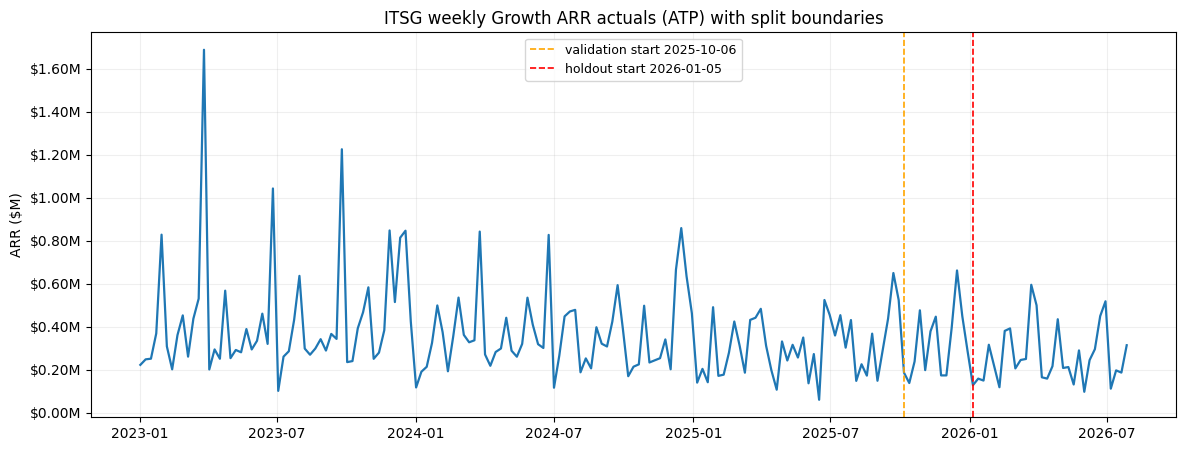

In [0]:
# STEP 2: ITSG EXPLORATORY DATA ANALYSIS AND THREE-WAY BACKTEST SPLIT
# =============================================================================
# PURPOSE: (1) Visualise the time series to build intuition about level,
# seasonality, and noise; (2) partition data into three non-overlapping regions
# with strict temporal separation.
#
# Split design:
#   CV region       — everything before VALIDATION_START; walk-forward CV lives here
#   Validation slice— 13 weeks (2025-10-06 → 2025-12-29); tuning ONLY
#   Holdout         — >= 2026-01-05; untouched until final leaderboard
#
# Outputs:
#   model_df, train_df, test_df, validation_df, cv_region_df
#   BACKTEST_START, VALIDATION_START constants
#
# CHANGED vs V4: adds the 13-week validation (tuning) slice between the CV
# region and the holdout. All tuning happens there and only there.
# =============================================================================

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker


def millions(x, pos):
    return f'${x:,.2f}M'


BACKTEST_START = pd.Timestamp('2026-01-05')   # holdout boundary (unchanged)
VALIDATION_WEEKS = 13

model_df = weekly_itsg[['ds', 'y']].copy().sort_values('ds').reset_index(drop=True)
pre_holdout_weeks = model_df.loc[model_df['ds'] < BACKTEST_START, 'ds'].tolist()
assert len(pre_holdout_weeks) > VALIDATION_WEEKS + 52, 'Not enough history for the three-way split.'
VALIDATION_START = pre_holdout_weeks[-VALIDATION_WEEKS]

model_df['split'] = np.where(
    model_df['ds'] >= BACKTEST_START, 'holdout',
    np.where(model_df['ds'] >= VALIDATION_START, 'validation', 'cv_region')
)
train_df = model_df[model_df['ds'] < BACKTEST_START].copy()          # all pre-holdout (final retrain)
test_df = model_df[model_df['ds'] >= BACKTEST_START].copy()          # untouched holdout
validation_df = model_df[model_df['split'] == 'validation'].copy()   # tuning only
cv_region_df = model_df[model_df['split'] == 'cv_region'].copy()

assert len(validation_df) == VALIDATION_WEEKS
assert cv_region_df['ds'].max() < VALIDATION_START
assert validation_df['ds'].max() < BACKTEST_START

eda_summary = pd.DataFrame([
    {'metric': 'weeks', 'value': f"{len(weekly_itsg):,}"},
    {'metric': 'start_date', 'value': str(weekly_itsg['ds'].min().date())},
    {'metric': 'end_date', 'value': str(weekly_itsg['ds'].max().date())},
    {'metric': 'total_arr_m', 'value': f"{weekly_itsg['y'].sum() / 1e6:,.2f}"},
    {'metric': 'avg_weekly_arr_m', 'value': f"{weekly_itsg['y'].mean() / 1e6:,.3f}"},
    {'metric': 'weekly_cv_pct', 'value': f"{100.0 * weekly_itsg['y'].std() / max(weekly_itsg['y'].mean(), 1):,.1f}"},
    {'metric': 'markets', 'value': ', '.join(ALL_MARKETS)},
])
display(eda_summary)

split_summary = pd.DataFrame([
    {'split': name, 'rows': len(frame), 'start': str(frame['ds'].min().date()),
     'end': str(frame['ds'].max().date()), 'arr_m': round(frame['y'].sum() / 1e6, 3)}
    for name, frame in [('cv_region', cv_region_df), ('validation', validation_df), ('holdout', test_df)]
])
print('Three-way split (validation slice is for tuning ONLY — never reported as accuracy):')
display(split_summary)

total_market_actuals = (
    weekly_itsg_by_market.groupby('sales_market', as_index=False)
    .agg(total_arr=('y', 'sum'))
    .assign(pct=lambda d: (100 * d['total_arr'] / d['total_arr'].sum()).round(1))
    .sort_values('total_arr', ascending=False)
)
display(total_market_actuals)

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(weekly_itsg['ds'], weekly_itsg['y'] / 1e6, linewidth=1.6, color='#1f77b4')
ax.axvline(VALIDATION_START, color='orange', ls='--', lw=1.2, label=f'validation start {VALIDATION_START.date()}')
ax.axvline(BACKTEST_START, color='red', ls='--', lw=1.2, label=f'holdout start {BACKTEST_START.date()}')
ax.set_title('ITSG weekly Growth ARR actuals (ATP) with split boundaries')
ax.set_ylabel('ARR ($M)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(millions))
ax.grid(alpha=0.2)
ax.legend(fontsize=9)
plt.show()

### Step 3 — Walk-forward validation framework **(CHANGED — clean folds, tunable training window)**

Expanding-window walk-forward CV built **only from the CV region**, with the fold count computed from
available history (5 folds x 13 weeks with the current data) and asserts that no fold's train or test
window touches the validation slice or holdout — V4's 8 hardcoded folds trained into the holdout.

Two further corrections. First, V4 hardcoded a 78-week rolling training window ("recency weighting")
justified by narrative, and applied it to the benchmarks but not to LightGBM. Here the window length is a
**per-model hyperparameter** (78 / 104 / all weeks), applied inside each model's fit function via
`tail(window)` so CV, validation, holdout, and production all use identical logic, and *chosen on the
validation slice* like every other setting. Second, all shared metric code lives here (WAPE/MAPE/MPE/
sMAPE/RMSE + interval coverage), with quantile-ordering and interval helpers carried over from V4 —
except that interval width calibration for the statistical models now comes from **CV residuals** (clean)
rather than holdout residuals.

In [0]:
# STEP 3: WALK-FORWARD VALIDATION FRAMEWORK
# =============================================================================
# PURPOSE: Define walk-forward expanding-window CV folds and the validation-
# slice tuning helper.  Each fold trains on all data up to a cutoff, then
# tests on the next 13 weeks (one quarter).  Produces the fold specification
# and tune_on_validation() used by every model in Steps 4–6.
#
# Design:
#   * Expanding training window (each fold sees more history)
#   * Fixed 13-week test horizon (= 1 fiscal quarter)
#   * Minimum 79 weeks training ensures stable estimates
#   * All folds ENTIRELY within the CV region (pre-validation)
#   * tune_on_validation(): trains on CV region, scores on validation slice
#
# Outputs:
#   fold_specs     — DataFrame with fold boundaries
#   CV_FOLDS       — number of folds (5 with current history)
#   tune_on_validation() / best_candidate() — tuning helpers
#
# CHANGED vs V4:
#   * Folds built ONLY from cv_region_df; fold count computed; boundaries
#     asserted (V4: 8 hardcoded folds, folds 7-8 trained inside the holdout).
#   * Training-window length is a tunable per-model hyperparameter applied
#     via tail(window) inside fit functions (V4: hardcoded 78, inconsistently
#     applied).
#   * tune_on_validation(): the ONE place hyperparameters are chosen.
# UNCHANGED: metric definitions, quantile-order enforcement, calendar features.
# =============================================================================

import warnings
from dataclasses import dataclass

import holidays
import mlflow
from prophet import Prophet
from statsforecast import StatsForecast
from statsforecast.models import AutoETS, MSTL
from statsmodels.tsa.holtwinters import ExponentialSmoothing

warnings.filterwarnings('ignore')

CV_HORIZON = 13
CV_MIN_TRAIN_FLOOR = 79
N_CV_WEEKS = len(cv_region_df)
CV_FOLDS = int(min(6, (N_CV_WEEKS - CV_MIN_TRAIN_FLOOR) // CV_HORIZON))
assert CV_FOLDS >= 3, f'Only {CV_FOLDS} clean folds available — check split constants.'
MIN_TRAIN_WEEKS = N_CV_WEEKS - CV_FOLDS * CV_HORIZON
FULL_WINDOW = 10_000   # sentinel: use all available history
us_holidays = holidays.US()


def add_calendar_columns(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    out['ds'] = pd.to_datetime(out['ds'])
    out['year'] = out['ds'].dt.year
    out['quarter'] = out['ds'].dt.quarter
    out['week_of_qtr'] = out.groupby(['year', 'quarter']).cumcount() + 1
    out['quarter_end_flag'] = (out['week_of_qtr'] >= 11).astype(int)
    out['is_q4'] = (out['quarter'] == 4).astype(int)
    out['q4_week_countdown'] = np.where(out['quarter'] == 4, 14 - out['week_of_qtr'], 0)
    out['woq_sin'] = np.sin(2 * np.pi * out['week_of_qtr'] / 13.0)
    out['woq_cos'] = np.cos(2 * np.pi * out['week_of_qtr'] / 13.0)
    out['qtr_sin'] = np.sin(2 * np.pi * out['quarter'] / 4.0)
    out['qtr_cos'] = np.cos(2 * np.pi * out['quarter'] / 4.0)
    out['us_holiday_binary'] = out['ds'].apply(lambda d: int(d.date() in us_holidays or (d + pd.Timedelta(days=1)).date() in us_holidays))
    return out


def ci_coverage(actual, p10, p90):
    actual = np.asarray(actual, dtype=float)
    p10 = np.asarray(p10, dtype=float)
    p90 = np.asarray(p90, dtype=float)
    valid = np.isfinite(actual) & np.isfinite(p10) & np.isfinite(p90)
    if not valid.any():
        return np.nan
    return float(100.0 * np.mean((actual[valid] >= p10[valid]) & (actual[valid] <= p90[valid])))


def forecast_metrics(actual, forecast, p10=None, p90=None):
    actual = np.asarray(actual, dtype=float)
    forecast = np.asarray(forecast, dtype=float)
    assert actual.shape == forecast.shape, f'Metric shape mismatch: {actual.shape} vs {forecast.shape}'
    denom = np.clip(np.abs(actual).sum(), 1e-9, None)
    mask = np.abs(actual) > 1e-9
    wape = 100.0 * np.abs(actual - forecast).sum() / denom
    mape = 100.0 * np.mean(np.abs((actual[mask] - forecast[mask]) / actual[mask])) if mask.any() else np.nan
    mpe = 100.0 * np.mean((forecast[mask] - actual[mask]) / actual[mask]) if mask.any() else np.nan
    smape_denom = np.abs(actual) + np.abs(forecast)
    smape = np.nanmean(np.where(smape_denom > 1e-9, 200.0 * np.abs(actual - forecast) / smape_denom, np.nan))
    rmse = np.sqrt(np.nanmean((actual - forecast) ** 2))
    out = {'wape': float(wape), 'mape': float(mape), 'mpe': float(mpe), 'smape': float(smape), 'rmse': float(rmse)}
    out['ci_coverage'] = ci_coverage(actual, p10, p90) if p10 is not None and p90 is not None else np.nan
    return out


@dataclass
class FoldSpec:
    fold: int
    train_start: pd.Timestamp
    train_end: pd.Timestamp
    test_start: pd.Timestamp
    test_end: pd.Timestamp
    train_rows: int
    test_rows: int


def build_walkforward_folds(df: pd.DataFrame, horizon: int = CV_HORIZON, n_folds: int = CV_FOLDS, min_train: int = MIN_TRAIN_WEEKS):
    df = df.sort_values('ds').reset_index(drop=True)
    specs = []
    for fold_idx in range(n_folds):
        train_end_idx = min_train + fold_idx * horizon
        test_end_idx = train_end_idx + horizon
        tr = df.iloc[:train_end_idx]
        te = df.iloc[train_end_idx:test_end_idx]
        specs.append(FoldSpec(fold_idx + 1, tr['ds'].min(), tr['ds'].max(), te['ds'].min(), te['ds'].max(), len(tr), len(te)))
    return specs


fold_specs = build_walkforward_folds(cv_region_df[['ds', 'y']])
fold_spec_df = pd.DataFrame([s.__dict__ for s in fold_specs])
# Fix guards: every fold (train AND test) ends before the validation slice
assert (pd.to_datetime(fold_spec_df['train_end']) < VALIDATION_START).all(), 'CV fold trains past VALIDATION_START!'
assert (pd.to_datetime(fold_spec_df['test_end']) < VALIDATION_START).all(), 'CV fold tests past VALIDATION_START!'
assert (pd.to_datetime(fold_spec_df['test_end']) < BACKTEST_START).all()


def run_walkforward_cv(model_name, fit_predict_fn, df, **kwargs):
    """Shared expanding-window CV. df must be the CV region only; asserted per fold.
    fit_predict_fn(train_hist, horizon, **kwargs) -> np.array of length horizon."""
    df = df.sort_values('ds').reset_index(drop=True)
    fold_rows, fold_preds = [], []
    for spec in fold_specs:
        train_fold = df[df['ds'] <= spec.train_end].copy()
        test_fold = df[(df['ds'] >= spec.test_start) & (df['ds'] <= spec.test_end)].copy()
        assert train_fold['ds'].max() < VALIDATION_START, f'{model_name} fold {spec.fold} trains past VALIDATION_START'
        assert test_fold['ds'].max() < BACKTEST_START, f'{model_name} fold {spec.fold} tests inside holdout'
        pred = np.asarray(fit_predict_fn(train_fold, horizon=len(test_fold), **kwargs), dtype=float)
        m = forecast_metrics(test_fold['y'].values, pred)
        fold_rows.append({'model': model_name, 'fold': spec.fold,
                          'train_start': str(train_fold['ds'].min().date()), 'train_end': str(train_fold['ds'].max().date()),
                          'test_start': str(test_fold['ds'].min().date()), 'test_end': str(test_fold['ds'].max().date()),
                          'train_rows': len(train_fold), 'test_rows': len(test_fold),
                          **{k: round(v, 3) for k, v in m.items() if k != 'ci_coverage'}})
        fold_preds.append(pd.DataFrame({'model': model_name, 'fold': spec.fold, 'ds': test_fold['ds'],
                                        'actual': test_fold['y'].values, 'forecast': pred}))
    fold_df = pd.DataFrame(fold_rows)
    summary = {'model': model_name, 'folds': len(fold_df)}
    for k in ['wape', 'mape', 'mpe', 'smape', 'rmse']:
        summary[f'mean_{k}'] = round(fold_df[k].mean(), 3)
        summary[f'std_{k}'] = round(fold_df[k].std(ddof=0), 3)
    return fold_df, pd.DataFrame([summary]), pd.concat(fold_preds, ignore_index=True)


VALIDATION_HORIZON = len(validation_df)
validation_actuals = validation_df['y'].to_numpy(dtype=float)


def tune_on_validation(model_name, fit_predict_fn, series_df, candidate_grid, fixed_kwargs=None):
    """Train on the CV region, score a 13-week forecast on the validation slice.
    The ONLY place hyperparameters are chosen. Failed candidates -> inf."""
    fixed_kwargs = fixed_kwargs or {}
    tuning_train = series_df[series_df['ds'] < VALIDATION_START].copy().reset_index(drop=True)
    tuning_valid = series_df[(series_df['ds'] >= VALIDATION_START) & (series_df['ds'] < BACKTEST_START)].copy()
    assert len(tuning_valid) == VALIDATION_HORIZON
    rows = []
    for candidate in candidate_grid:
        row = {'model': model_name}
        row.update({k: (str(v) if isinstance(v, (list, tuple, dict)) else v) for k, v in candidate.items()})
        try:
            pred = np.asarray(fit_predict_fn(tuning_train.copy(), horizon=VALIDATION_HORIZON, **candidate, **fixed_kwargs), dtype=float)
            m = forecast_metrics(tuning_valid['y'].values, pred)
            row.update({'val_wape': round(m['wape'], 3), 'val_mape': round(m['mape'], 3), 'val_mpe': round(m['mpe'], 3), 'error': ''})
        except Exception as exc:
            row.update({'val_wape': np.inf, 'val_mape': np.inf, 'val_mpe': np.nan, 'error': str(exc)[:160]})
        rows.append(row)
    result = pd.DataFrame(rows).sort_values('val_wape').reset_index(drop=True)
    if not np.isfinite(result['val_wape'].iloc[0]):
        raise RuntimeError(f'All {model_name} tuning candidates failed on the validation slice.')
    return result


def best_candidate(tuning_table, candidate_grid):
    best_idx, best_wape = None, np.inf
    for i, candidate in enumerate(candidate_grid):
        key = {k: (str(v) if isinstance(v, (list, tuple, dict)) else v) for k, v in candidate.items()}
        match = tuning_table
        for k, v in key.items():
            match = match[match[k] == v]
        if len(match) and np.isfinite(match['val_wape'].iloc[0]) and match['val_wape'].iloc[0] < best_wape:
            best_wape, best_idx = float(match['val_wape'].iloc[0]), i
    assert best_idx is not None
    return candidate_grid[best_idx]


def compute_woq_seasonal_profile(train_hist: pd.DataFrame) -> pd.DataFrame:
    profile_frame = add_calendar_columns(train_hist[['ds', 'y']].copy())
    profile = profile_frame.groupby('week_of_qtr', as_index=False).agg(woq_level=('y', 'mean'))
    scale = profile['woq_level'].mean()
    profile['woq_factor'] = np.where(scale > 1e-9, profile['woq_level'] / scale, 1.0)
    profile['woq_factor'] = profile['woq_factor'].replace([np.inf, -np.inf], np.nan).fillna(1.0)
    return profile[['week_of_qtr', 'woq_factor']]


def enforce_quantile_order(frame: pd.DataFrame, p10_col='p10', p50_col='p50', p90_col='p90') -> pd.DataFrame:
    out = frame.copy()
    for c in [p10_col, p50_col, p90_col]:
        out[c] = pd.to_numeric(out[c], errors='coerce').fillna(0.0).clip(lower=0.0)
    out[p10_col] = np.minimum(out[p10_col], out[p50_col])
    out[p90_col] = np.maximum(out[p90_col], out[p50_col])
    return out


def derive_interval_adjustments(history_frame, actual_col='actual', forecast_col='forecast',
                                lower_q=0.10, upper_q=0.90, fallback=(-0.15, 0.20)):
    """Relative-error quantiles from a residual frame. v2: call this with CV
    predictions (clean), not holdout predictions."""
    if history_frame.empty:
        return fallback
    actual = pd.to_numeric(history_frame[actual_col], errors='coerce')
    forecast = pd.to_numeric(history_frame[forecast_col], errors='coerce')
    ratios = np.where(np.abs(forecast) > 1e-9, (actual - forecast) / forecast, np.nan)
    ratios = pd.Series(ratios).replace([np.inf, -np.inf], np.nan).dropna().clip(lower=-0.9, upper=3.0)
    if ratios.empty:
        return fallback
    lower = min(float(np.nanquantile(ratios, lower_q)), 0.0)
    upper = max(float(np.nanquantile(ratios, upper_q)), 0.0)
    if lower > upper:
        return fallback
    return lower, upper


def apply_interval_adjustments(forecast_frame, lower_adj, upper_adj, forecast_col='forecast'):
    out = forecast_frame.copy()
    out['forecast'] = pd.to_numeric(out[forecast_col], errors='coerce').fillna(0.0).clip(lower=0.0)
    out['p10'] = out['forecast'] * (1.0 + lower_adj)
    out['p50'] = out['forecast']
    out['p90'] = out['forecast'] * (1.0 + upper_adj)
    return enforce_quantile_order(out, 'p10', 'p50', 'p90')


print(f'CV region weeks: {N_CV_WEEKS} | folds: {CV_FOLDS} | horizon: {CV_HORIZON} | minimum train: {MIN_TRAIN_WEEKS}')
print(f'Boundaries: CV end {cv_region_df["ds"].max().date()} < validation {VALIDATION_START.date()} < holdout {BACKTEST_START.date()}')
print(f'Validation slice actual: ${validation_df["y"].sum()/1e6:.3f}M over {VALIDATION_HORIZON} weeks')
print('\nFold specification (all strictly pre-validation, pre-holdout):')
display(fold_spec_df)

CV region weeks: 144 | folds: 5 | horizon: 13 | minimum train: 79
Boundaries: CV end 2025-09-29 < validation 2025-10-06 < holdout 2026-01-05
Validation slice actual: $4.200M over 13 weeks

Fold specification (all strictly pre-validation, pre-holdout):


fold,train_start,train_end,test_start,test_end,train_rows,test_rows
1,2023-01-02T00:00:00.000Z,2024-07-01T00:00:00.000Z,2024-07-08T00:00:00.000Z,2024-09-30T00:00:00.000Z,79,13
2,2023-01-02T00:00:00.000Z,2024-09-30T00:00:00.000Z,2024-10-07T00:00:00.000Z,2024-12-30T00:00:00.000Z,92,13
3,2023-01-02T00:00:00.000Z,2024-12-30T00:00:00.000Z,2025-01-06T00:00:00.000Z,2025-03-31T00:00:00.000Z,105,13
4,2023-01-02T00:00:00.000Z,2025-03-31T00:00:00.000Z,2025-04-07T00:00:00.000Z,2025-06-30T00:00:00.000Z,118,13
5,2023-01-02T00:00:00.000Z,2025-06-30T00:00:00.000Z,2025-07-07T00:00:00.000Z,2025-09-29T00:00:00.000Z,131,13


### Step 4 — Benchmark models: Prophet, MSTL, ETS **(CHANGED — tuned grids, clean CV/holdout)**

Same three statistical baselines as V4, with each model's settings — including the training-window
length — selected on the validation slice: Prophet (`changepoint_prior_scale` x window), ETS
(window x seasonal type, damped trend), MSTL (seasonal periods x window; the 52-week component requires
≥104 training weeks so short windows are excluded for it). All forecasts are clipped at zero **inside the
fit functions**, so CV, holdout, and production apply identical post-processing. CV runs on the clean CV
region via the shared framework; holdout forecasts retrain on all pre-holdout data with the frozen tuned
settings. No expected-accuracy numbers appear in comments — V4's hand-typed figures did not match its own
output.

14:20:31 - cmdstanpy - INFO - Chain [1] start processing
14:20:31 - cmdstanpy - INFO - Chain [1] done processing
14:20:31 - cmdstanpy - INFO - Chain [1] start processing
14:20:31 - cmdstanpy - INFO - Chain [1] done processing
14:20:31 - cmdstanpy - INFO - Chain [1] start processing
14:20:31 - cmdstanpy - INFO - Chain [1] done processing
14:20:31 - cmdstanpy - INFO - Chain [1] start processing
14:20:31 - cmdstanpy - INFO - Chain [1] done processing
14:20:31 - cmdstanpy - INFO - Chain [1] start processing
14:20:31 - cmdstanpy - INFO - Chain [1] done processing
14:20:32 - cmdstanpy - INFO - Chain [1] start processing
14:20:32 - cmdstanpy - INFO - Chain [1] done processing


Tuned benchmark hyperparameters (frozen from validation slice):
  Prophet_trend : {'changepoint_prior_scale': 0.03, 'window': 78}
  ETS           : {'window': 78, 'seasonal': 'add'}
  MSTL_v2       : {'season_length': (13, 52), 'window': 104}

Prophet tuning table:


model,changepoint_prior_scale,window,val_wape,val_mape,val_mpe,error
Prophet_trend,0.03,78,35.61,38.97,13.38,
Prophet_trend,0.05,78,35.625,39.021,13.504,
Prophet_trend,0.1,78,35.659,39.142,13.792,
Prophet_trend,0.05,10000,43.558,47.287,13.613,
Prophet_trend,0.03,10000,43.673,46.989,12.27,
Prophet_trend,0.1,10000,43.707,46.9,11.873,



ETS tuning table:


model,window,seasonal,val_wape,val_mape,val_mpe,error
ETS,78,add,31.167,34.339,5.942,
ETS,104,mul,32.459,42.548,20.268,
ETS,104,add,33.826,33.336,10.352,
ETS,10000,mul,34.646,46.602,28.696,
ETS,78,mul,35.348,41.411,19.146,
ETS,10000,add,47.966,64.453,36.413,


...

14:20:35 - cmdstanpy - INFO - Chain [1] start processing
14:20:35 - cmdstanpy - INFO - Chain [1] done processing
14:20:36 - cmdstanpy - INFO - Chain [1] start processing
14:20:36 - cmdstanpy - INFO - Chain [1] done processing
14:20:36 - cmdstanpy - INFO - Chain [1] start processing
14:20:36 - cmdstanpy - INFO - Chain [1] done processing
14:20:36 - cmdstanpy - INFO - Chain [1] start processing
14:20:36 - cmdstanpy - INFO - Chain [1] done processing
14:20:36 - cmdstanpy - INFO - Chain [1] start processing
14:20:36 - cmdstanpy - INFO - Chain [1] done processing
14:20:36 - cmdstanpy - INFO - Chain [1] start processing
14:20:36 - cmdstanpy - INFO - Chain [1] done processing



Benchmark walk-forward summary (clean CV region):


model,folds,mean_wape,std_wape,mean_mape,std_mape,mean_mpe,std_mpe,mean_smape,std_smape,mean_rmse,std_rmse
Prophet_trend,5,35.737,4.808,49.051,19.211,26.854,23.659,35.81,4.12,153828.618,30181.714
MSTL_v2,5,37.115,7.275,42.797,16.926,13.589,21.278,35.921,7.641,173570.635,37804.829
ETS,5,38.872,9.9,50.01,25.682,25.188,31.295,39.365,7.587,166169.069,21351.729



Benchmark holdout summary (Q1 2026 onward, never tuned against):


model,test_start,test_end,test_rows,wape,mape,mpe,smape,rmse
ETS,2026-01-05,2026-07-27,30,29.319,38.198,29.373,30.376,89387.295
MSTL_v2,2026-01-05,2026-07-27,30,30.406,32.964,2.585,32.835,101304.464
Prophet_trend,2026-01-05,2026-07-27,30,32.181,42.449,34.604,32.846,96718.67


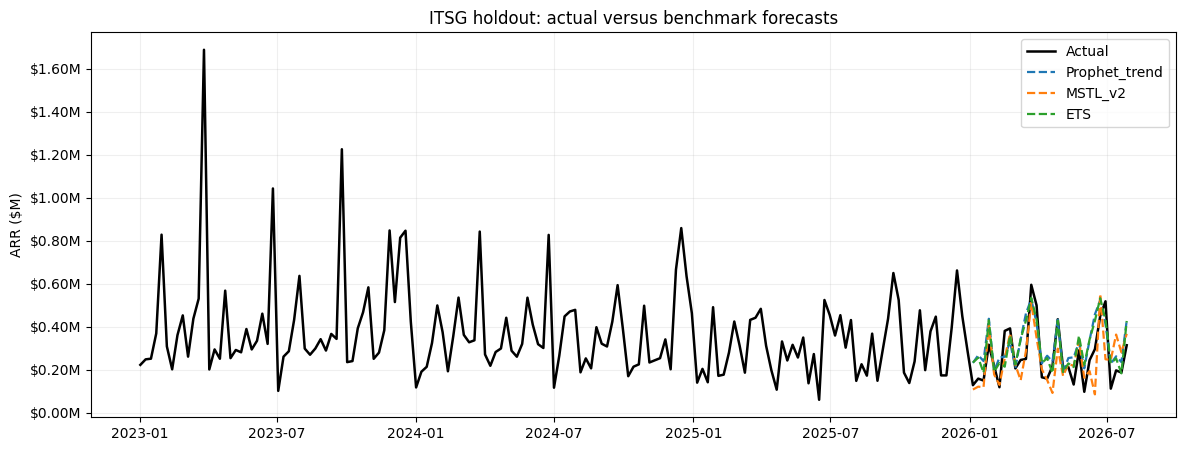

model,quarter,weeks,actual_arr,forecast_arr,actual_arr_m,forecast_arr_m,pct_error
ETS,2026Q1,13,3656858.65,4062280.094578846,3.657,4.062,11.09
MSTL_v2,2026Q1,13,3656858.65,3204476.7609381787,3.657,3.204,-12.37
Prophet_trend,2026Q1,13,3656858.65,4170823.110023925,3.657,4.171,14.05
ETS,2026Q2,13,3420233.27,4039688.321199378,3.42,4.04,18.11
MSTL_v2,2026Q2,13,3420233.27,2935534.953970003,3.42,2.936,-14.17
Prophet_trend,2026Q2,13,3420233.27,4129840.2832585145,3.42,4.13,20.75
ETS,2026Q3,4,809161.41,1092253.4852621173,0.809,1.092,34.99
MSTL_v2,2026Q3,4,809161.41,1256481.148888717,0.809,1.256,55.28
Prophet_trend,2026Q3,4,809161.41,1153313.9762025825,0.809,1.153,42.53


Note: 2026Q3 is quarter-to-date through 2026-07-27.


In [0]:
# STEP 4: BENCHMARK MODELS AND DIAGNOSTICS
# =============================================================================
# PURPOSE: Fit three statistical baseline models on the CV region, score them
# via walk-forward CV, then retrain on all pre-holdout data for the holdout
# evaluation.  These three form the core of the Adaptive Ensemble (Step 7).
#
# Models trained here:
#   Prophet_trend — Meta Prophet with custom quarterly Fourier seasonality
#                   and empirical WoQ seasonal overlay (no built-in seasonality)
#   MSTL_v2       — STL decomposition + AutoETS on remainder (statsforecast)
#   ETS           — Holt-Winters Exponential Smoothing (statsmodels)
#
# Outputs:
#   cv_benchmark_summary       — per-model CV WAPE across folds
#   holdout_benchmark_predictions — weekly holdout forecasts for all models
#   holdout_benchmark_summary  — leaderboard (WAPE, bias, directional accuracy)
#   BEST_*_PARAMS              — frozen hyperparameters for production
#
# CHANGED vs V4:
#   * Hyperparameters (incl. training window) tuned on the validation slice.
#     V4 hardcoded cps=0.05 and a 78-week window chosen from holdout-era
#     reasoning.
#   * CV on the clean CV region via the shared framework (Fix: no holdout
#     contact).
#   * Non-negativity clip inside each fit function (identical in CV /
#     holdout / production).
# UNCHANGED: model lineup and names, WoQ seasonal overlay for Prophet,
#   MLflow logging, holdout plot, quarterly comparison.
# =============================================================================

def fit_predict_prophet_trend(train_hist, horizon, changepoint_prior_scale=0.05, window=FULL_WINDOW):
    hist = train_hist[['ds', 'y']].tail(min(window, len(train_hist))).copy()
    future_dates = pd.DataFrame({'ds': pd.date_range(hist['ds'].max() + pd.Timedelta(weeks=1), periods=horizon, freq='W-MON')})
    future_input = add_calendar_columns(future_dates)
    woq_profile = compute_woq_seasonal_profile(hist)
    future_input = future_input.merge(woq_profile, on='week_of_qtr', how='left')
    future_input['woq_factor'] = future_input['woq_factor'].fillna(1.0)
    model = Prophet(
        yearly_seasonality=False, weekly_seasonality=False, daily_seasonality=False,
        seasonality_mode='additive',
        changepoint_prior_scale=changepoint_prior_scale,
        changepoint_range=0.85,
        n_changepoints=min(8, max(1, len(hist) // 20)),
    )
    model.fit(hist)
    fcst = model.predict(future_dates)
    # Non-negativity inside the predict path (identical everywhere)
    return np.clip(fcst['yhat'].to_numpy() * future_input['woq_factor'].to_numpy(), 0.0, None)


def fit_predict_mstl_v2(train_hist, horizon, season_length=(13, 52), window=FULL_WINDOW):
    hist = train_hist[['ds', 'y']].tail(min(window, len(train_hist))).copy()
    hist.insert(0, 'unique_id', 'itsg_total')
    sf = StatsForecast(models=[MSTL(season_length=list(season_length), trend_forecaster=AutoETS(model='ZZN'))], freq='W-MON', n_jobs=1)
    fcst = sf.forecast(df=hist, h=horizon)
    model_col = [c for c in fcst.columns if c not in {'unique_id', 'ds'}][0]
    return np.clip(fcst[model_col].to_numpy(dtype=float), 0.0, None)


def fit_predict_ets(train_hist, horizon, window=FULL_WINDOW, seasonal='mul', damped=True):
    values = pd.to_numeric(train_hist['y'], errors='coerce').fillna(0.0).tail(min(window, len(train_hist)))
    if seasonal == 'mul':
        values = values.clip(lower=1.0)   # multiplicative seasonality needs strictly positive values
    seasonal_periods = 52 if len(values) >= 104 else 13
    fitted = ExponentialSmoothing(
        values, trend='add', damped_trend=damped, seasonal=seasonal,
        seasonal_periods=seasonal_periods, initialization_method='estimated',
    ).fit(optimized=True, use_brute=True)
    return np.clip(fitted.forecast(horizon).to_numpy(dtype=float), 0.0, None)


# --- Grids, tuned ONLY on the validation slice ---------------------------------
prophet_grid = [{'changepoint_prior_scale': cps, 'window': w} for cps in (0.03, 0.05, 0.10) for w in (78, FULL_WINDOW)]
ets_grid = [{'window': w, 'seasonal': s} for w in (78, 104, FULL_WINDOW) for s in ('add', 'mul')]
mstl_grid = [{'season_length': sl, 'window': w} for sl in ((13, 52), (4, 13, 52)) for w in (104, FULL_WINDOW)]

series_total = model_df[['ds', 'y']].copy()
prophet_tuning = tune_on_validation('Prophet_trend', fit_predict_prophet_trend, series_total, prophet_grid)
ets_tuning = tune_on_validation('ETS', fit_predict_ets, series_total, ets_grid)
mstl_tuning = tune_on_validation('MSTL_v2', fit_predict_mstl_v2, series_total, mstl_grid)

BEST_PROPHET_PARAMS = best_candidate(prophet_tuning, prophet_grid)
BEST_ETS_PARAMS = best_candidate(ets_tuning, ets_grid)
BEST_MSTL_PARAMS = best_candidate(mstl_tuning, mstl_grid)

print('Tuned benchmark hyperparameters (frozen from validation slice):')
print(f'  Prophet_trend : {BEST_PROPHET_PARAMS}')
print(f'  ETS           : {BEST_ETS_PARAMS}')
print(f'  MSTL_v2       : {BEST_MSTL_PARAMS}')
print('\nProphet tuning table:')
display(prophet_tuning)
print('\nETS tuning table:')
display(ets_tuning)
print('\nMSTL tuning table:')
display(mstl_tuning)

# --- Clean CV + holdout ---------------------------------------------------------
benchmark_model_specs = [
    ('Prophet_trend', fit_predict_prophet_trend, BEST_PROPHET_PARAMS),
    ('MSTL_v2', fit_predict_mstl_v2, BEST_MSTL_PARAMS),
    ('ETS', fit_predict_ets, BEST_ETS_PARAMS),
]

cv_fold_frames, cv_summary_frames, cv_pred_frames = [], [], []
holdout_pred_frames, holdout_rows = [], []
for model_name, fit_fn, kwargs in benchmark_model_specs:
    fold_df, summary_df, pred_df = run_walkforward_cv(model_name, fit_fn, cv_region_df[['ds', 'y']].copy(), **kwargs)
    cv_fold_frames.append(fold_df)
    cv_summary_frames.append(summary_df)
    cv_pred_frames.append(pred_df)

    holdout_pred = np.asarray(fit_fn(train_df[['ds', 'y']].copy(), horizon=len(test_df), **kwargs), dtype=float)
    holdout_pred_frames.append(pd.DataFrame({'model': model_name, 'ds': test_df['ds'].values,
                                             'actual': test_df['y'].values, 'forecast': holdout_pred}))
    hm = forecast_metrics(test_df['y'].values, holdout_pred)
    holdout_rows.append({'model': model_name, 'test_start': str(test_df['ds'].min().date()),
                         'test_end': str(test_df['ds'].max().date()), 'test_rows': len(test_df),
                         **{k: round(v, 3) for k, v in hm.items() if k != 'ci_coverage'}})

    with mlflow.start_run(run_name=f'itsg_benchmark_{model_name.lower()}_v2', nested=False):
        mlflow.log_param('model_name', model_name)
        mlflow.log_param('product_group', PRODUCT_SCOPE)
        mlflow.log_param('cv_folds', CV_FOLDS)
        mlflow.log_param('cv_region_end', str(cv_region_df['ds'].max().date()))
        mlflow.log_param('validation_slice', f'{VALIDATION_START.date()}..{validation_df["ds"].max().date()}')
        mlflow.log_param('tuned_params', str(kwargs))
        for k, v in summary_df.iloc[0].to_dict().items():
            if k not in ('model',) and pd.notna(v):
                mlflow.log_metric(str(k), float(v))
        for k in ['wape', 'mape', 'mpe', 'smape', 'rmse']:
            mlflow.log_metric(f'holdout_{k}', float(holdout_rows[-1][k]))

cv_fold_metrics = pd.concat(cv_fold_frames, ignore_index=True)
cv_benchmark_summary = pd.concat(cv_summary_frames, ignore_index=True).sort_values('mean_wape').reset_index(drop=True)
cv_fold_predictions = pd.concat(cv_pred_frames, ignore_index=True)
holdout_benchmark_predictions = pd.concat(holdout_pred_frames, ignore_index=True)
holdout_benchmark_summary = pd.DataFrame(holdout_rows).sort_values('wape').reset_index(drop=True)

print('\nBenchmark walk-forward summary (clean CV region):')
display(cv_benchmark_summary)
print('\nBenchmark holdout summary (Q1 2026 onward, never tuned against):')
display(holdout_benchmark_summary)

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(model_df['ds'], model_df['y'] / 1e6, color='black', linewidth=1.8, label='Actual')
for model_name in ['Prophet_trend', 'MSTL_v2', 'ETS']:
    tmp = holdout_benchmark_predictions[holdout_benchmark_predictions['model'] == model_name]
    ax.plot(tmp['ds'], tmp['forecast'] / 1e6, linewidth=1.6, ls='--', label=model_name)
ax.set_title('ITSG holdout: actual versus benchmark forecasts')
ax.set_ylabel('ARR ($M)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(millions))
ax.grid(alpha=0.2)
ax.legend()
plt.show()

# Quarterly comparison — quarters via to_period (V4 mixed three Q1 definitions)
quarterly_compare = holdout_benchmark_predictions.copy()
quarterly_compare['quarter'] = quarterly_compare['ds'].dt.to_period('Q').astype(str)
quarterly_compare = (
    quarterly_compare.groupby(['model', 'quarter'], as_index=False)
    .agg(weeks=('ds', 'nunique'), actual_arr=('actual', 'sum'), forecast_arr=('forecast', 'sum'))
)
quarterly_compare['actual_arr_m'] = (quarterly_compare['actual_arr'] / 1e6).round(3)
quarterly_compare['forecast_arr_m'] = (quarterly_compare['forecast_arr'] / 1e6).round(3)
quarterly_compare['pct_error'] = np.where(
    quarterly_compare['actual_arr'].abs() > 1e-9,
    (100.0 * (quarterly_compare['forecast_arr'] - quarterly_compare['actual_arr']) / quarterly_compare['actual_arr']).round(2),
    np.nan,
)
display(quarterly_compare.sort_values(['quarter', 'model']))
last_q = weekly_itsg['ds'].max().to_period('Q')
if int((weekly_itsg['ds'].dt.to_period('Q') == last_q).sum()) < 13:
    print(f'Note: {last_q} is quarter-to-date through {weekly_itsg["ds"].max().date()}.')

### Step 5 — Benchmark model: DHR-ARIMA **(CHANGED — training-only future regressors, tuned order, fallback)**

Dynamic Harmonic Regression + AutoARIMA at the total level (as in V4 — ITSG's markets are too thin for
per-market ARIMA), with Fourier terms and external regressors (created pipeline, headcount, pipeline
velocity, win rate, quarter-end and holiday flags) built on the complete spine. Changes: (1) **future
regressors come from training-only week-of-quarter median profiles** — V4 fed actual future
`forecast_prophet` rows into the forecast horizon, and its future win-rate silently collapsed to zero
because future `y` is NaN; (2) the Fourier harmonic order and training window are tuned on the validation
slice; (3) AutoARIMA is wrapped with a seasonal-naive fallback; (4) forecasts are clipped at zero inside
the predict function. Win rate remains a backward-shifted rolling ratio of won ARR to created pipeline —
`all_created_arr` is an all-outcome series, so there is no survivorship issue.

In [0]:
# STEP 5: BENCHMARK MODEL — DHR-ARIMA (TOTAL LEVEL)
# =============================================================================
# PURPOSE: Fit Dynamic Harmonic Regression + AutoARIMA at the total level
# (ITSG's markets are too thin for per-market ARIMA), with Fourier terms
# and external regressors, then evaluate via CV and holdout.
#
# Model design:
#   Total-level only (all markets summed) — unlike UCC which fits per-market
#   Fourier seasonality (period=13, tuned K)
#   External regressors: created_pipeline_lag4, headcount_lag4,
#     pipeline_velocity_lag4, win_rate_woq, quarter_end_flag, us_holiday
#   Future regressors: WoQ median profiles from training only (no lookahead)
#   Fallback: seasonal naive if AutoARIMA fails to converge
#
# CHANGED vs V4:
#   * Future xreg = training-only WoQ median profiles (V4 used future
#     forecast_prophet values and a future win-rate that collapsed to 0).
#   * Fourier order and training window tuned on the validation slice.
#   * try/except seasonal-naive fallback; non-negativity clip inside predict.
#   * CV via the shared clean framework.
# =============================================================================

from statsforecast.models import AutoARIMA

DHR_MODEL_NAME = 'DHR_ARIMA'
DHR_BASE_XCOLS = ['created_lag4', 'headcount_lag4', 'pipeline_velocity_lag4',
                  'quarter_end_flag', 'us_holiday_binary', 'win_rate_woq']
DHR_MAX_FOURIER_K = 2


def dhr_fourier_cols(k):
    cols = []
    for order in range(1, k + 1):
        for period in (13, 52):
            cols += [f'sin_{period}_{order}', f'cos_{period}_{order}']
    return cols


def add_dhr_fourier(df):
    out = df.copy()
    woy = pd.to_datetime(out['ds']).dt.isocalendar().week.astype(int).values
    woq = out['week_of_qtr'].values
    for order in range(1, DHR_MAX_FOURIER_K + 1):
        for period in (13, 52):
            idx = woq if period == 13 else woy
            out[f'sin_{period}_{order}'] = np.sin(2 * np.pi * order * (idx - 1) / period)
            out[f'cos_{period}_{order}'] = np.cos(2 * np.pi * order * (idx - 1) / period)
    return out


def build_total_dhr_frame() -> pd.DataFrame:
    total = feature_source_total_hist.copy().sort_values('ds').reset_index(drop=True)
    total['pipeline_velocity'] = (total['all_created_arr'] / total['headcount'].replace(0, np.nan)).replace([np.inf, -np.inf], np.nan).fillna(0.0)
    total['created_lag4'] = total['all_created_arr'].shift(4).fillna(0.0)
    total['headcount_lag4'] = total['headcount'].shift(4).bfill().fillna(0.0)
    total['pipeline_velocity_lag4'] = total['pipeline_velocity'].shift(4).fillna(0.0)
    # Backward-shifted rolling conversion: won ARR / created pipeline (all-outcome)
    _won_roll = total['y'].shift(1).rolling(4, min_periods=1).sum()
    _created_roll = total['all_created_arr'].shift(1).rolling(4, min_periods=1).sum().replace(0, np.nan)
    total['win_rate_woq'] = (_won_roll / _created_roll).clip(0.0, 3.0).fillna(0.0)
    total = add_calendar_columns(total)
    total = add_dhr_fourier(total)
    all_cols = dhr_fourier_cols(DHR_MAX_FOURIER_K) + DHR_BASE_XCOLS
    total[all_cols] = total[all_cols].replace([np.inf, -np.inf], np.nan).fillna(0.0)
    return total


def build_future_dhr_xreg(train_feat: pd.DataFrame, horizon: int) -> pd.DataFrame:
    # CHANGED (leak-safety): dynamic regressors for future weeks come from
    # training-only WoQ median profiles, never from future table values.
    future = pd.DataFrame({'ds': pd.date_range(train_feat['ds'].max() + pd.Timedelta(weeks=1), periods=horizon, freq='W-MON')})
    future = add_calendar_columns(future)
    future = add_dhr_fourier(future)
    lookback = train_feat.sort_values('ds').tail(104)
    for col in ['created_lag4', 'headcount_lag4', 'pipeline_velocity_lag4', 'win_rate_woq']:
        profile = lookback.groupby('week_of_qtr')[col].median().to_dict()
        default = float(lookback[col].median()) if len(lookback) else 0.0
        future[col] = [profile.get(wk, default) for wk in future['week_of_qtr']]
    future['quarter_end_flag'] = future['quarter_end_flag'].astype(float)
    all_cols = dhr_fourier_cols(DHR_MAX_FOURIER_K) + DHR_BASE_XCOLS
    future[all_cols] = future[all_cols].replace([np.inf, -np.inf], np.nan).fillna(0.0)
    return future


def fit_predict_dhr_arima(train_hist, horizon, full_feature_df, fourier_k=2, window=FULL_WINDOW):
    x_cols = dhr_fourier_cols(fourier_k) + DHR_BASE_XCOLS
    train_end = pd.to_datetime(train_hist['ds']).max()
    train_feat = full_feature_df[full_feature_df['ds'] <= train_end].copy().tail(min(window, len(full_feature_df)))
    future_feat = build_future_dhr_xreg(train_feat, horizon)
    train_input = train_feat[['ds', 'y'] + x_cols].copy()
    train_input.insert(0, 'unique_id', 'itsg_total')
    future_input = future_feat[['ds'] + x_cols].copy()
    future_input.insert(0, 'unique_id', 'itsg_total')
    try:
        sf = StatsForecast(models=[AutoARIMA(season_length=13)], freq='W-MON', n_jobs=1)
        fcst = sf.forecast(df=train_input, h=horizon, X_df=future_input)
        model_col = [c for c in fcst.columns if c not in {'unique_id', 'ds'}][0]
        pred = fcst[model_col].to_numpy(dtype=float)
    except Exception as exc:
        print(f'WARNING: AutoARIMA failed ({type(exc).__name__}: {exc}); using seasonal-naive fallback.')
        hist = train_input.sort_values('ds')['y'].to_numpy(dtype=float)
        season = hist[-13:] if len(hist) >= 13 else hist
        pred = np.tile(season, int(np.ceil(horizon / max(1, len(season)))))[:horizon]
    # Non-negativity inside the predict path (identical everywhere)
    return np.clip(pred, 0.0, None)


dhr_df = build_total_dhr_frame()
assert len(dhr_df) == len(weekly_itsg)
assert np.allclose(dhr_df['y'].values, weekly_itsg.sort_values('ds')['y'].values, atol=1.0)

# --- Tune on the validation slice ----------------------------------------------
dhr_grid = [{'fourier_k': k, 'window': w} for k in (1, 2) for w in (104, FULL_WINDOW)]
dhr_tuning = tune_on_validation(DHR_MODEL_NAME, fit_predict_dhr_arima, dhr_df[['ds', 'y']].copy(), dhr_grid,
                                fixed_kwargs={'full_feature_df': dhr_df})
BEST_DHR_PARAMS = best_candidate(dhr_tuning, dhr_grid)
print(f'Tuned DHR params: {BEST_DHR_PARAMS}')
display(dhr_tuning)

# --- Clean CV + holdout ----------------------------------------------------------
dhr_fold_df, dhr_summary_df, dhr_pred_df = run_walkforward_cv(
    DHR_MODEL_NAME, fit_predict_dhr_arima, cv_region_df[['ds', 'y']].copy(),
    full_feature_df=dhr_df, **BEST_DHR_PARAMS,
)
dhr_holdout_pred = np.asarray(
    fit_predict_dhr_arima(train_df[['ds', 'y']].copy(), horizon=len(test_df), full_feature_df=dhr_df, **BEST_DHR_PARAMS),
    dtype=float,
)
dhr_hm = forecast_metrics(test_df['y'].values, dhr_holdout_pred)
dhr_holdout_row = pd.DataFrame([{'model': DHR_MODEL_NAME, 'test_start': str(test_df['ds'].min().date()),
                                 'test_end': str(test_df['ds'].max().date()), 'test_rows': len(test_df),
                                 **{k: round(v, 3) for k, v in dhr_hm.items() if k != 'ci_coverage'}}])
dhr_holdout_predictions = pd.DataFrame({'model': DHR_MODEL_NAME, 'ds': test_df['ds'].values,
                                        'actual': test_df['y'].values, 'forecast': dhr_holdout_pred})

cv_fold_metrics = pd.concat([cv_fold_metrics[cv_fold_metrics['model'] != DHR_MODEL_NAME], dhr_fold_df], ignore_index=True)
cv_benchmark_summary = pd.concat([cv_benchmark_summary[cv_benchmark_summary['model'] != DHR_MODEL_NAME], dhr_summary_df],
                                 ignore_index=True).sort_values('mean_wape').reset_index(drop=True)
cv_fold_predictions = pd.concat([cv_fold_predictions[cv_fold_predictions['model'] != DHR_MODEL_NAME], dhr_pred_df], ignore_index=True)
holdout_benchmark_summary = pd.concat([holdout_benchmark_summary[holdout_benchmark_summary['model'] != DHR_MODEL_NAME], dhr_holdout_row],
                                      ignore_index=True).sort_values('wape').reset_index(drop=True)
holdout_benchmark_predictions = pd.concat([holdout_benchmark_predictions[holdout_benchmark_predictions['model'] != DHR_MODEL_NAME],
                                           dhr_holdout_predictions], ignore_index=True)

with mlflow.start_run(run_name='itsg_benchmark_dhr_arima_v2', nested=False):
    mlflow.log_param('model_name', DHR_MODEL_NAME)
    mlflow.log_param('product_group', PRODUCT_SCOPE)
    mlflow.log_param('level', 'total')
    mlflow.log_param('tuned_params', str(BEST_DHR_PARAMS))
    mlflow.log_param('future_xreg_strategy', 'training_only_woq_profiles')
    for k, v in dhr_summary_df.iloc[0].to_dict().items():
        if k != 'model' and pd.notna(v):
            mlflow.log_metric(str(k), float(v))
    for k in ['wape', 'mape', 'mpe', 'smape', 'rmse']:
        mlflow.log_metric(f'holdout_{k}', float(dhr_holdout_row.iloc[0][k]))

print('\nUpdated CV summary including DHR-ARIMA:')
display(cv_benchmark_summary)
print('\nUpdated holdout summary:')
display(holdout_benchmark_summary)

Tuned DHR params: {'fourier_k': 2, 'window': 104}


model,fourier_k,window,val_wape,val_mape,val_mpe,error
DHR_ARIMA,2,104,44.583,63.393,50.5,
DHR_ARIMA,1,104,45.8,61.81,42.47,
DHR_ARIMA,1,10000,47.099,62.347,43.808,
DHR_ARIMA,2,10000,47.608,61.695,43.21,



Updated CV summary including DHR-ARIMA:


model,folds,mean_wape,std_wape,mean_mape,std_mape,mean_mpe,std_mpe,mean_smape,std_smape,mean_rmse,std_rmse
Prophet_trend,5,35.737,4.808,49.051,19.211,26.854,23.659,35.81,4.12,153828.618,30181.714
MSTL_v2,5,37.115,7.275,42.797,16.926,13.589,21.278,35.921,7.641,173570.635,37804.829
ETS,5,38.872,9.9,50.01,25.682,25.188,31.295,39.365,7.587,166169.069,21351.729
DHR_ARIMA,5,40.255,8.615,61.654,25.358,46.879,28.059,39.608,6.731,166775.303,36991.53



Updated holdout summary:


model,test_start,test_end,test_rows,wape,mape,mpe,smape,rmse
ETS,2026-01-05,2026-07-27,30,29.319,38.198,29.373,30.376,89387.295
MSTL_v2,2026-01-05,2026-07-27,30,30.406,32.964,2.585,32.835,101304.464
Prophet_trend,2026-01-05,2026-07-27,30,32.181,42.449,34.604,32.846,96718.67
DHR_ARIMA,2026-01-05,2026-07-27,30,41.391,57.045,45.167,40.369,130851.938


### Step 6 — Global LightGBM quantile model **(CHANGED — complete-spine panel, deterministic, tuned, gated)**

One gradient-boosted quantile model (p10/p50/p90) trained across all five markets, with recursive
week-by-week prediction (V4's recursive design is kept — it correctly matches production inference).
The substantive fixes:

- **Panel rebuilt on the complete week x market spine.** The target comes from SFDC ATP on the full grid
  (zero weeks are $0, not missing); `forecast_prophet` columns are left-joined as features and
  forward-filled within each market. V4 used `forecast_prophet`'s rows as the spine (~84% coverage), which
  punched holes in the target and lag features and produced its ~120% holdout WAPE.
- **Deterministic training** (`deterministic=true`, `force_row_wise`, single thread, fixed seed) so
  reruns on identical data reproduce identical results.
- **Recursive prediction keeps 60 weeks of history**, so `y_lag26`/`y_lag52` stay populated (V4 kept 26
  weeks, zeroing those lags at prediction time only — a train/serve skew).
- **Evaluation at the weekly total level** with the shared metric code, so LGB is directly comparable to
  the other four models (V4 scored it per market row, where near-zero actuals make MAPE meaningless);
  market-level WAPE is reported as a diagnostic.
- **Hyperparameters tuned on the validation slice** (leaves x learning rate x min-leaf), CV folds
  replicated exactly from the shared specification (asserted).
- **Data-driven ensemble promotion gate:** LGB joins the production ensemble only if its validation-slice
  WAPE is within 1.25x the best benchmark's — the decision is computed and printed, not hardcoded.
  V4's dead-code features (`deal_count_lag1`, `qe_deal_ramp` — engineered but never in the feature list)
  are removed.

In [0]:
# STEP 6: GLOBAL LIGHTGBM QUANTILE (ITSG ONLY, GLOBAL BY MARKET)
# =============================================================================
# PURPOSE: Train one gradient-boosted quantile model across all five markets
# simultaneously ("global" panel training), producing p10/p50/p90 weekly
# forecasts.  Uses recursive multi-step prediction with exponential recency
# sample weights.
#
# Key design choices:
#   * Panel built on COMPLETE week x market spine (V4's 72% coverage was the
#     root cause of its ~120% holdout WAPE — target rows were missing)
#   * deterministic=True, force_row_wise=True, num_threads=1 for bitwise
#     reproducibility across runs and team members
#   * qe_proximity / qe_proximity_sq (continuous 0→1 ramp for weeks 9–13)
#   * Recursive predictor keeps 60 weeks of history (V4 kept 26, starving
#     y_lag26/52 at prediction time)
#   * Data-driven promotion gate: included in ensemble only if validation
#     WAPE <= 1.25 x best benchmark's validation WAPE
#
# CHANGED vs V4:
#   * Panel on the COMPLETE week x market spine; target from SFDC ATP;
#     forecast_prophet joined as features only (root-cause fix for the ~120%
#     holdout WAPE).
#   * Deterministic LGB params; tuned on the validation slice.
#   * Recursive predictor keeps 60 weeks of history (V4: 26 -> starved lags).
#   * Metrics at weekly TOTAL level (+ market-level diagnostic).
#   * CV folds asserted identical to the shared fold specification.
#   * Ensemble inclusion decided by a printed validation gate, not a comment.
# UNCHANGED: quantile lineup, early stopping, recursive design, region
#   holidays, MLflow + Unity Catalog registry (now wrapped defensively).
# =============================================================================

import lightgbm as lgb
import holidays as holidays_lib

GLOBAL_MODEL_NAME = 'Global_LGB_Q50_ITSG'
GLOBAL_QUANTILES = {'P10': 0.10, 'P50': 0.50, 'P90': 0.90}
GLOBAL_CAT_COLS = ['sales_market']
GLOBAL_EARLYSTOP_WEEKS = 13
RECURSIVE_HISTORY_WEEKS = 60   # >= 53 so y_lag52 / yoy stay populated (V4 used 26)
GLOBAL_FEATURE_COLS = [
    'week_of_qtr', 'quarter_end_flag', 'is_q4', 'q4_week_countdown',
    'qe_proximity', 'qe_proximity_sq',
    'woq_sin', 'woq_cos', 'qtr_sin', 'qtr_cos',
    'sales_market',
    'created_lag4', 'created_lag5', 'headcount_lag4', 'win_rate_woq',
    'pipeline_velocity_lag4', 'deal_size_lag1', 'sales_cycle_lag1',
    'push_ctr_lag1', 'avg_opportunity_age', 'avg_dials_lag4', 'avg_touches_lag4',
    'mc_actuals_lag4', 'mkt_opened_lag4', 'miradore_lag4', 'plan_gap_lag1', 'partner_pipe_lag4',
    'sales_rep_ramp_ratio', 'y_lag1', 'y_lag4', 'y_lag8', 'y_lag13', 'y_lag26', 'y_lag52',
    'r4w', 'rolling_vol_4w', 'rolling_vol_13w', 'yoy_growth', 'qoq_momentum',
    'us_holiday_binary', 'region_holiday',
]
BASE_LGB_PARAMS = {
    'objective': 'quantile',
    'feature_fraction': 0.9,
    'bagging_fraction': 0.9,
    'bagging_freq': 1,
    'lambda_l2': 1.0,
    'verbosity': -1,
    'seed': 42,
    'metric': 'quantile',
    # Determinism (lesson from the UCC rebuild: multi-threaded LGB flipped
    # near-tied tuning candidates between identical runs)
    'deterministic': True,
    'force_row_wise': True,
    'num_threads': 1,
}

REGION_HOLIDAY_COUNTRIES = {'NA': ['US'], 'EMEA': ['UK', 'DE'], 'APAC': ['IN'], 'LATAM': ['BR'], 'Unknown': ['US']}


def compute_region_holiday(ds_series: pd.Series, market_series: pd.Series) -> pd.Series:
    result = pd.Series(0, index=ds_series.index, dtype=int)
    for market, country_codes in REGION_HOLIDAY_COUNTRIES.items():
        mask = market_series.astype(str) == market
        if not mask.any():
            continue
        hol_dates = set()
        for cc in country_codes:
            try:
                for yr in range(2022, 2028):
                    hol_dates.update(holidays_lib.country_holidays(cc, years=yr).keys())
            except Exception:
                pass
        for idx in ds_series[mask].index:
            week_start = pd.to_datetime(ds_series[idx])
            if any(d.date() in hol_dates for d in pd.date_range(week_start, periods=7, freq='D')):
                result.loc[idx] = 1
    return result


def load_authoritative_actuals(start_date, end_date) -> pd.DataFrame:
    actuals = spark.sql(f"""
    SELECT
        CAST(period AS DATE) AS period_month,
        UPPER(COALESCE(market, 'Unknown')) AS sales_market,
        CAST(purchase_amount_in_usd_current_rate AS DOUBLE) AS authoritative_actuals
    FROM {AUTHORITATIVE_ACTUALS_TABLE}
    WHERE period >= ADD_MONTHS(DATE '{pd.Timestamp(start_date).date()}', -1)
      AND period <= DATE '{pd.Timestamp(end_date).date()}'
      AND UPPER(version) = 'ACTUALS'
      AND UPPER(COALESCE(product_genus, product_family, product_group, '')) = '{AUTHORITATIVE_ACTUALS_PRODUCT.upper()}'
      AND purchase_type = 'Growth'
    """).toPandas()
    if actuals.empty:
        return pd.DataFrame(columns=['month_key', 'sales_market', 'authoritative_actuals'])
    actuals['period_month'] = pd.to_datetime(actuals['period_month'], errors='coerce')
    actuals['sales_market'] = normalize_market(actuals['sales_market'])
    actuals['month_key'] = actuals['period_month'].dt.to_period('M').astype(str)
    return actuals.groupby(['month_key', 'sales_market'], as_index=False)['authoritative_actuals'].sum()


def _engineer_panel_features(panel: pd.DataFrame) -> pd.DataFrame:
    """Shared feature engineering for history and forward panels (per slice)."""
    panel = panel.sort_values(['slice_id', 'ds']).reset_index(drop=True)
    for col in FP_FEATURE_COLS + ['authoritative_actuals']:
        panel[col] = pd.to_numeric(panel[col], errors='coerce').fillna(0.0)
    # Continuous quarter-end proximity: 0 for weeks 1-8, ramps 0→1 for weeks 9-13
    panel['qe_proximity'] = np.maximum(0, panel['week_of_qtr'] - 8) / 5.0
    panel['qe_proximity_sq'] = panel['qe_proximity'] ** 2
    panel['pipeline_velocity'] = (panel['all_created_arr'] / panel['headcount'].replace(0, np.nan)).replace([np.inf, -np.inf], np.nan).fillna(0.0)
    panel['plan_gap'] = panel['miradore_plan'] - panel['y'].fillna(0.0)
    grouped = panel.groupby('slice_id', group_keys=False)
    panel['sales_rep_ramp_ratio'] = (
        grouped['headcount'].diff().clip(lower=0).fillna(0.0)
        .groupby(panel['slice_id']).transform(lambda s: s.rolling(26, min_periods=1).sum())
        / panel['headcount'].replace(0, np.nan)
    ).replace([np.inf, -np.inf], np.nan).fillna(0.0)
    panel['created_lag4'] = grouped['all_created_arr'].shift(4).fillna(0.0)
    panel['created_lag5'] = grouped['all_created_arr'].shift(5).fillna(0.0)
    panel['headcount_lag4'] = grouped['headcount'].shift(4)
    panel['headcount_lag4'] = panel.groupby('slice_id')['headcount_lag4'].ffill().bfill().fillna(0.0)
    panel['pipeline_velocity_lag4'] = grouped['pipeline_velocity'].shift(4).fillna(0.0)
    panel['deal_size_lag1'] = grouped['avg_deal_size'].shift(1).fillna(0.0)
    panel['sales_cycle_lag1'] = grouped['avg_sales_cycle'].shift(1).fillna(0.0)
    panel['push_ctr_lag1'] = grouped['avg_push_counter'].shift(1).fillna(0.0)
    panel['avg_dials_lag4'] = grouped['avg_dials'].shift(4).fillna(0.0)
    panel['avg_touches_lag4'] = grouped['avg_touches'].shift(4).fillna(0.0)
    panel['mc_actuals_lag4'] = grouped['authoritative_actuals'].shift(4).fillna(0.0)
    panel['mkt_opened_lag4'] = grouped['magna_carta_actuals'].shift(4).fillna(0.0)
    panel['miradore_lag4'] = grouped['miradore_plan'].shift(4).fillna(0.0)
    panel['partner_pipe_lag4'] = grouped['total_partner_pipeline'].shift(4).fillna(0.0)
    panel['plan_gap_lag1'] = grouped['plan_gap'].shift(1).fillna(0.0)
    for lag in [1, 4, 8, 13, 26, 52]:
        panel[f'y_lag{lag}'] = grouped['y'].shift(lag).fillna(0.0)
    panel['r4w'] = grouped['y'].transform(lambda s: s.shift(1).rolling(4, min_periods=1).mean()).fillna(0.0)
    panel['rolling_vol_4w'] = grouped['y'].transform(lambda s: s.shift(1).rolling(4, min_periods=2).std()).fillna(0.0)
    panel['rolling_vol_13w'] = grouped['y'].transform(lambda s: s.shift(1).rolling(13, min_periods=2).std()).fillna(0.0)
    _lag53_safe = grouped['y'].shift(53).replace(0, np.nan)
    panel['yoy_growth'] = ((panel['y_lag1'] / _lag53_safe) - 1.0).replace([np.inf, -np.inf], np.nan).clip(-3.0, 3.0).fillna(0.0)
    _lag13_safe = panel['y_lag13'].replace(0, np.nan)
    panel['qoq_momentum'] = ((panel['y_lag1'] / _lag13_safe) - 1.0).replace([np.inf, -np.inf], np.nan).clip(-3.0, 3.0).fillna(0.0)
    panel['region_holiday'] = compute_region_holiday(panel['ds'], panel['sales_market'])
    # win_rate_woq: shift-safe rolling conversion per slice x week-of-quarter
    panel['win_rate_woq'] = np.nan
    for (_sid, _wk), grp in panel.groupby(['slice_id', 'week_of_qtr']):
        won_roll = grp['y'].shift(1).rolling(4, min_periods=1).sum()
        created_roll = grp['all_created_arr'].shift(1).rolling(4, min_periods=1).sum().replace(0, np.nan)
        panel.loc[grp.index, 'win_rate_woq'] = (won_roll / created_roll).clip(0.0, 3.0).values
    global_rate = (
        panel.groupby('slice_id')['y'].transform(lambda s: s.shift(1).rolling(13, min_periods=1).sum()) /
        panel.groupby('slice_id')['all_created_arr'].transform(lambda s: s.shift(1).rolling(13, min_periods=1).sum()).replace(0, np.nan)
    ).clip(0.0, 3.0)
    panel['win_rate_woq'] = panel['win_rate_woq'].fillna(global_rate).fillna(0.0)
    for col in GLOBAL_FEATURE_COLS:
        if col not in panel.columns:
            panel[col] = 0.0
    fill_cols = [c for c in GLOBAL_FEATURE_COLS if c not in GLOBAL_CAT_COLS]
    panel[fill_cols] = panel[fill_cols].replace([np.inf, -np.inf], np.nan).fillna(0.0)
    return panel


def build_global_panel() -> pd.DataFrame:
    # CHANGED (root-cause fix): spine = COMPLETE week x market grid; target from
    # SFDC ATP; forecast_prophet features left-joined and ffilled per market.
    panel = market_calendar.merge(weekly_itsg_by_market[['ds', 'sales_market', 'y', 'deal_count']],
                                  on=['ds', 'sales_market'], how='left')
    panel[['y', 'deal_count']] = panel[['y', 'deal_count']].fillna(0.0)
    panel = panel.merge(feature_source_all.drop(columns=['fp_actuals_reference']),
                        on=['ds', 'sales_market'], how='left')
    panel['slice_id'] = PRODUCT_SCOPE + '|' + panel['sales_market']
    panel = panel.sort_values(['slice_id', 'ds']).reset_index(drop=True)
    for col in FP_FEATURE_COLS:
        panel[col] = panel.groupby('slice_id')[col].ffill()
    panel = add_calendar_columns(panel)
    panel['month_key'] = panel['ds'].dt.to_period('M').astype(str)
    auth = load_authoritative_actuals(panel['ds'].min(), panel['ds'].max())
    panel = panel.merge(auth, on=['month_key', 'sales_market'], how='left')
    return _engineer_panel_features(panel)


def fit_global_quantile_models(train_frame: pd.DataFrame, params: dict = None, quantiles: dict = None):
    params = dict(BASE_LGB_PARAMS | (params or {}))
    quantiles = quantiles or GLOBAL_QUANTILES
    train_weeks = sorted(train_frame['ds'].unique())
    if len(train_weeks) <= GLOBAL_EARLYSTOP_WEEKS:
        raise ValueError('Not enough training weeks for LGB early-stopping holdout.')
    valid_start = train_weeks[-GLOBAL_EARLYSTOP_WEEKS]
    fit_train = train_frame[train_frame['ds'] < valid_start]
    fit_valid = train_frame[train_frame['ds'] >= valid_start]
    X_train = fit_train[GLOBAL_FEATURE_COLS].copy()
    X_valid = fit_valid[GLOBAL_FEATURE_COLS].copy()
    for col in GLOBAL_CAT_COLS:
        X_train[col] = pd.Categorical(X_train[col], categories=GLOBAL_MARKETS)
        X_valid[col] = pd.Categorical(X_valid[col], categories=GLOBAL_MARKETS)
    train_ds = lgb.Dataset(X_train, label=fit_train['y'].astype(float), categorical_feature=GLOBAL_CAT_COLS, free_raw_data=False)
    valid_ds = lgb.Dataset(X_valid, label=fit_valid['y'].astype(float), categorical_feature=GLOBAL_CAT_COLS, reference=train_ds, free_raw_data=False)
    models = {}
    for label, alpha in quantiles.items():
        models[label] = lgb.train(params | {'alpha': alpha}, train_ds, num_boost_round=1500,
                                  valid_sets=[valid_ds], callbacks=[lgb.early_stopping(stopping_rounds=75, verbose=False)])
    p50_key = 'P50' if 'P50' in models else list(models.keys())[0]
    importance_df = pd.DataFrame({
        'feature': GLOBAL_FEATURE_COLS,
        'importance_gain': models[p50_key].feature_importance(importance_type='gain'),
        'importance_split': models[p50_key].feature_importance(importance_type='split'),
    }).sort_values('importance_gain', ascending=False).reset_index(drop=True)
    return models, importance_df


def recursive_lgb_predict(models, panel, predict_start, predict_end):
    """Recursive week-by-week prediction, identical in CV / holdout / production.
    Keeps RECURSIVE_HISTORY_WEEKS of history so long lags stay populated.
    Returns slice rows with p10/p50/p90 (clipped >= 0, ordered) and y_actual."""
    history_cutoff = pd.Timestamp(predict_start) - pd.Timedelta(weeks=RECURSIVE_HISTORY_WEEKS)
    work = panel[(panel['ds'] >= history_cutoff) & (panel['ds'] <= predict_end)].copy()
    work = work.sort_values(['slice_id', 'ds']).reset_index(drop=True)
    pred_mask = work['ds'] >= pd.Timestamp(predict_start)
    work['y_actual'] = work['y']
    work.loc[pred_mask, 'y'] = np.nan
    predict_weeks = sorted(work.loc[pred_mask, 'ds'].unique())
    preds = []
    for step_ds in predict_weeks:
        _grp = work.groupby('slice_id', group_keys=False)
        for lag in [1, 4, 8, 13, 26, 52]:
            work[f'y_lag{lag}'] = _grp['y'].shift(lag).fillna(0.0)
        work['r4w'] = _grp['y'].transform(lambda s: s.shift(1).rolling(4, min_periods=1).mean()).fillna(0.0)
        work['rolling_vol_4w'] = _grp['y'].transform(lambda s: s.shift(1).rolling(4, min_periods=2).std()).fillna(0.0)
        work['rolling_vol_13w'] = _grp['y'].transform(lambda s: s.shift(1).rolling(13, min_periods=2).std()).fillna(0.0)
        _lag53_safe = _grp['y'].shift(53).replace(0, np.nan)
        work['yoy_growth'] = ((work['y_lag1'] / _lag53_safe) - 1.0).replace([np.inf, -np.inf], np.nan).clip(-3.0, 3.0).fillna(0.0)
        _lag13_safe = work['y_lag13'].replace(0, np.nan)
        work['qoq_momentum'] = ((work['y_lag1'] / _lag13_safe) - 1.0).replace([np.inf, -np.inf], np.nan).clip(-3.0, 3.0).fillna(0.0)
        work['plan_gap'] = work['miradore_plan'] - work['y'].fillna(0.0)
        work['plan_gap_lag1'] = _grp['plan_gap'].shift(1).fillna(0.0)

        step_mask = work['ds'] == step_ds
        step_rows = work.loc[step_mask].copy()
        X_step = step_rows[GLOBAL_FEATURE_COLS].copy()
        for cat in GLOBAL_CAT_COLS:
            X_step[cat] = pd.Categorical(X_step[cat], categories=GLOBAL_MARKETS)
        for name in ['P10', 'P50', 'P90']:
            if name in models:
                step_rows[name.lower()] = np.clip(models[name].predict(X_step, num_iteration=models[name].best_iteration), 0.0, None)
        if 'p10' not in step_rows.columns:
            step_rows['p10'] = step_rows['p50']
        if 'p90' not in step_rows.columns:
            step_rows['p90'] = step_rows['p50']
        work.loc[step_mask, 'y'] = step_rows['p50'].values   # feed p50 back
        preds.append(step_rows)
    result = pd.concat(preds, ignore_index=True)
    return enforce_quantile_order(result, 'p10', 'p50', 'p90')


global_panel = build_global_panel()
# Root-cause sanity checks (the V4 failure mode)
assert global_panel.groupby('ds').size().nunique() == 1, 'Panel must be a complete week x market grid.'
_panel_total = global_panel.groupby('ds')['y'].sum().sort_index()
assert np.allclose(_panel_total.values, weekly_itsg.sort_values('ds')['y'].values, atol=1.0), \
    'LGB panel target does not reconcile to weekly_itsg.y.'
print(f'LGB panel: {len(global_panel):,} rows = {global_panel["ds"].nunique()} weeks x {global_panel["sales_market"].nunique()} markets (complete grid)')

validation_weeks_list = sorted(validation_df['ds'].tolist())

# --- Tune on the validation slice (P50 only for speed) --------------------------
lgb_grid = [{'num_leaves': nl, 'learning_rate': lr, 'min_data_in_leaf': mdl}
            for nl in (15, 31) for lr in (0.03, 0.06) for mdl in (10, 20)]
lgb_tuning_rows = []
for candidate in lgb_grid:
    row = dict(candidate)
    try:
        cand_models, _ = fit_global_quantile_models(global_panel[global_panel['ds'] < VALIDATION_START], params=candidate, quantiles={'P50': 0.50})
        cand_pred = recursive_lgb_predict(cand_models, global_panel, VALIDATION_START, validation_df['ds'].max())
        cand_weekly = cand_pred.groupby('ds', as_index=False)['p50'].sum().sort_values('ds')
        m = forecast_metrics(validation_actuals, cand_weekly['p50'].to_numpy(dtype=float))
        row.update({'val_wape': round(m['wape'], 3), 'val_mape': round(m['mape'], 3), 'val_mpe': round(m['mpe'], 3), 'error': ''})
    except Exception as exc:
        row.update({'val_wape': np.inf, 'val_mape': np.inf, 'val_mpe': np.nan, 'error': str(exc)[:160]})
    lgb_tuning_rows.append(row)
lgb_tuning = pd.DataFrame(lgb_tuning_rows).sort_values('val_wape').reset_index(drop=True)
assert np.isfinite(lgb_tuning['val_wape'].iloc[0]), 'All LGB tuning candidates failed.'
BEST_LGB_PARAMS = {'num_leaves': int(lgb_tuning.iloc[0]['num_leaves']),
                   'min_data_in_leaf': int(lgb_tuning.iloc[0]['min_data_in_leaf']),
                   'learning_rate': float(lgb_tuning.iloc[0]['learning_rate'])}
print(f'Tuned LGB params (deterministic training): {BEST_LGB_PARAMS}')
display(lgb_tuning)

# --- Ensemble promotion gate (validation slice only) -----------------------------
LGB_VALIDATION_WAPE = float(lgb_tuning['val_wape'].iloc[0])
BENCHMARK_VALIDATION_WAPES = {
    'Prophet_trend': float(prophet_tuning['val_wape'].iloc[0]),
    'MSTL_v2': float(mstl_tuning['val_wape'].iloc[0]),
    'ETS': float(ets_tuning['val_wape'].iloc[0]),
    'DHR_ARIMA': float(dhr_tuning['val_wape'].iloc[0]),
}
LGB_GATE_THRESHOLD = 1.25 * min(BENCHMARK_VALIDATION_WAPES.values())
LGB_IN_ENSEMBLE = LGB_VALIDATION_WAPE <= LGB_GATE_THRESHOLD
print(f'\nLGB ensemble gate: validation WAPE {LGB_VALIDATION_WAPE:.2f} vs threshold {LGB_GATE_THRESHOLD:.2f} '
      f'(1.25 x best benchmark) -> {"INCLUDED in" if LGB_IN_ENSEMBLE else "EXCLUDED from"} the production ensemble')

# --- Clean CV replicating shared folds -------------------------------------------
lgb_cv_rows, lgb_cv_pred_frames = [], []
for spec in fold_specs:
    fold_train = global_panel[global_panel['ds'] <= spec.train_end]
    assert fold_train['ds'].max() < VALIDATION_START
    fold_models, _ = fit_global_quantile_models(fold_train, params=BEST_LGB_PARAMS)
    fold_pred = recursive_lgb_predict(fold_models, global_panel, spec.test_start, spec.test_end)
    fold_weekly = fold_pred.groupby('ds', as_index=False).agg(actual=('y_actual', 'sum'), forecast=('p50', 'sum'),
                                                              p10=('p10', 'sum'), p90=('p90', 'sum')).sort_values('ds')
    m = forecast_metrics(fold_weekly['actual'].values, fold_weekly['forecast'].values, fold_weekly['p10'].values, fold_weekly['p90'].values)
    lgb_cv_rows.append({'model': GLOBAL_MODEL_NAME, 'fold': spec.fold,
                        'train_start': str(fold_train['ds'].min().date()), 'train_end': str(fold_train['ds'].max().date()),
                        'test_start': str(spec.test_start.date()), 'test_end': str(spec.test_end.date()),
                        'train_rows': fold_train['ds'].nunique(), 'test_rows': len(fold_weekly),
                        'wape': round(m['wape'], 3), 'mape': round(m['mape'], 3), 'mpe': round(m['mpe'], 3),
                        'smape': round(m['smape'], 3), 'rmse': round(m['rmse'], 3),
                        'ci_coverage': round(m['ci_coverage'], 1) if pd.notna(m['ci_coverage']) else np.nan})
    lgb_cv_pred_frames.append(pd.DataFrame({'model': GLOBAL_MODEL_NAME, 'fold': spec.fold, 'ds': fold_weekly['ds'].values,
                                            'actual': fold_weekly['actual'].values, 'forecast': fold_weekly['forecast'].values}))

lgb_cv_fold_results = pd.DataFrame(lgb_cv_rows)
lgb_cv_summary_row = {'model': GLOBAL_MODEL_NAME, 'folds': len(lgb_cv_fold_results)}
for k in ['wape', 'mape', 'mpe', 'smape', 'rmse']:
    lgb_cv_summary_row[f'mean_{k}'] = round(lgb_cv_fold_results[k].mean(), 3)
    lgb_cv_summary_row[f'std_{k}'] = round(lgb_cv_fold_results[k].std(ddof=0), 3)
global_cv_summary = pd.DataFrame([lgb_cv_summary_row])
global_cv_predictions = pd.concat(lgb_cv_pred_frames, ignore_index=True)

# --- Holdout: retrain on all pre-holdout weeks; evaluate at TOTAL level ----------
global_quantile_models, global_feature_importance = fit_global_quantile_models(
    global_panel[global_panel['ds'] < BACKTEST_START], params=BEST_LGB_PARAMS)
global_test_predictions = recursive_lgb_predict(global_quantile_models, global_panel, BACKTEST_START, global_panel['ds'].max())
global_holdout_weekly = (
    global_test_predictions.groupby('ds', as_index=False)
    .agg(actual=('y_actual', 'sum'), forecast=('p50', 'sum'), p10=('p10', 'sum'), p90=('p90', 'sum'))
    .sort_values('ds')
)
ghm = forecast_metrics(global_holdout_weekly['actual'].values, global_holdout_weekly['forecast'].values,
                       global_holdout_weekly['p10'].values, global_holdout_weekly['p90'].values)
global_holdout_summary = pd.DataFrame([{'model': GLOBAL_MODEL_NAME,
                                        'test_start': str(global_holdout_weekly['ds'].min().date()),
                                        'test_end': str(global_holdout_weekly['ds'].max().date()),
                                        'test_rows': len(global_holdout_weekly),
                                        'wape': round(ghm['wape'], 3), 'mape': round(ghm['mape'], 3),
                                        'mpe': round(ghm['mpe'], 3), 'smape': round(ghm['smape'], 3),
                                        'rmse': round(ghm['rmse'], 3),
                                        'ci_coverage': round(ghm['ci_coverage'], 1) if pd.notna(ghm['ci_coverage']) else np.nan}])
# Market-level diagnostic (NOT the headline metric — near-zero slices distort %)
_slice_m = forecast_metrics(global_test_predictions['y_actual'].values, global_test_predictions['p50'].values)
print(f'LGB holdout — TOTAL weekly WAPE: {ghm["wape"]:.2f}% | market-slice diagnostic WAPE: {_slice_m["wape"]:.2f}%')

# --- Merge into shared result frames ----------------------------------------------
cv_benchmark_summary = pd.concat([cv_benchmark_summary[cv_benchmark_summary['model'] != GLOBAL_MODEL_NAME],
                                  global_cv_summary], ignore_index=True).sort_values('mean_wape').reset_index(drop=True)
cv_fold_metrics = pd.concat([cv_fold_metrics[cv_fold_metrics['model'] != GLOBAL_MODEL_NAME],
                             lgb_cv_fold_results.drop(columns=['ci_coverage'])], ignore_index=True)
cv_fold_predictions = pd.concat([cv_fold_predictions[cv_fold_predictions['model'] != GLOBAL_MODEL_NAME],
                                 global_cv_predictions], ignore_index=True)
holdout_benchmark_summary = pd.concat([holdout_benchmark_summary[holdout_benchmark_summary['model'] != GLOBAL_MODEL_NAME],
                                       global_holdout_summary], ignore_index=True).sort_values('wape').reset_index(drop=True)
holdout_benchmark_predictions = pd.concat([
    holdout_benchmark_predictions[holdout_benchmark_predictions['model'] != GLOBAL_MODEL_NAME],
    global_holdout_weekly.rename(columns={'forecast': 'forecast'}).assign(model=GLOBAL_MODEL_NAME)[['model', 'ds', 'actual', 'forecast']],
], ignore_index=True)

# --- MLflow + Unity Catalog registry (defensive) -----------------------------------
with mlflow.start_run(run_name='itsg_global_lgb_quantile_cv_v2', nested=False):
    mlflow.log_param('model_name', GLOBAL_MODEL_NAME)
    mlflow.log_param('panel_spine', 'complete_week_x_market_grid_sfdc_target')
    mlflow.log_param('tuned_params', str(BEST_LGB_PARAMS))
    mlflow.log_param('deterministic', True)
    mlflow.log_param('recursive_history_weeks', RECURSIVE_HISTORY_WEEKS)
    mlflow.log_param('lgb_in_ensemble', bool(LGB_IN_ENSEMBLE))
    mlflow.log_param('cv_folds', CV_FOLDS)
    for k, v in global_cv_summary.iloc[0].to_dict().items():
        if k != 'model' and pd.notna(v):
            mlflow.log_metric(str(k), float(v))
    for k in ['wape', 'mape', 'mpe', 'smape', 'rmse', 'ci_coverage']:
        v = global_holdout_summary.iloc[0][k]
        if pd.notna(v):
            mlflow.log_metric(f'holdout_{k}', float(v))
    try:
        mlflow.set_registry_uri('databricks-uc')
        LGB_REGISTERED_MODEL_NAME = 'datagroup_mdl.mdl_sales_analytics.itsg_global_lgb_p50'
        from mlflow.models import infer_signature
        _sample_X = global_panel[global_panel['ds'] < BACKTEST_START][GLOBAL_FEATURE_COLS].head(5).copy()
        for cat in GLOBAL_CAT_COLS:
            _sample_X[cat] = pd.Categorical(_sample_X[cat], categories=GLOBAL_MARKETS)
        _sig = infer_signature(_sample_X, global_quantile_models['P50'].predict(_sample_X, num_iteration=global_quantile_models['P50'].best_iteration))
        mlflow.lightgbm.log_model(global_quantile_models['P50'], name='lgb_p50_model',
                                  signature=_sig, registered_model_name=LGB_REGISTERED_MODEL_NAME)
        print(f'LGB P50 registered: {LGB_REGISTERED_MODEL_NAME}')
    except Exception as exc:
        print(f'Model registry step skipped ({type(exc).__name__}: {exc}) — training results are unaffected.')

print('\nGlobal LGB CV summary (weekly total level, clean folds):')
display(global_cv_summary)
print('\nGlobal LGB CV fold detail (incl. per-fold CI coverage):')
display(lgb_cv_fold_results)
print('\nGlobal LGB holdout summary (weekly total level):')
display(global_holdout_summary)
print('\nTop LGB feature importance:')
display(global_feature_importance.head(15))
print('\nUpdated CV / holdout leaderboards:')
display(cv_benchmark_summary)
display(holdout_benchmark_summary)

LGB panel: 935 rows = 187 weeks x 5 markets (complete grid)
Tuned LGB params (deterministic training): {'num_leaves': 15, 'min_data_in_leaf': 20, 'learning_rate': 0.03}


num_leaves,learning_rate,min_data_in_leaf,val_wape,val_mape,val_mpe,error
15,0.03,20,35.114,37.788,10.127,
15,0.06,10,35.644,37.603,8.645,
31,0.06,10,35.646,39.691,14.317,
15,0.06,20,35.694,40.384,14.37,
31,0.03,10,35.98,38.383,9.765,
31,0.03,20,36.7,40.349,12.516,
15,0.03,10,37.621,39.775,9.515,
31,0.06,20,37.907,42.198,14.945,



LGB ensemble gate: validation WAPE 35.11 vs threshold 38.96 (1.25 x best benchmark) -> INCLUDED in the production ensemble
LGB holdout — TOTAL weekly WAPE: 32.45% | market-slice diagnostic WAPE: 45.21%


🔗 View Logged Model at: https://goto-data-dock.cloud.databricks.com/ml/experiments/3857927908253278/models/m-05e0cfa3741e4e04b28ae159223e55fb?o=3197847567724351
Registered model 'datagroup_mdl.mdl_sales_analytics.itsg_global_lgb_p50' already exists. Creating a new version of this model...


Uploading artifacts:   0%|          | 0/9 [00:00<?, ?it/s]

...


Top LGB feature importance:


feature,importance_gain,importance_split
sales_market,1275.0105953216553,26
r4w,1022.8635163009167,86
rolling_vol_13w,846.40944647789,58
week_of_qtr,805.3645587265491,158
y_lag13,226.91343382000923,77
plan_gap_lag1,180.63623677939177,57
y_lag1,177.15848430991173,41
y_lag26,113.94137327373028,75
qoq_momentum,105.85972921550274,62
y_lag4,78.6094254553318,53



Updated CV / holdout leaderboards:


model,folds,mean_wape,std_wape,mean_mape,std_mape,mean_mpe,std_mpe,mean_smape,std_smape,mean_rmse,std_rmse
Prophet_trend,5,35.737,4.808,49.051,19.211,26.854,23.659,35.81,4.12,153828.618,30181.714
Global_LGB_Q50_ITSG,5,35.93,3.858,45.288,15.19,14.353,28.096,37.747,3.872,153740.812,38403.804
MSTL_v2,5,37.115,7.275,42.797,16.926,13.589,21.278,35.921,7.641,173570.635,37804.829
ETS,5,38.872,9.9,50.01,25.682,25.188,31.295,39.365,7.587,166169.069,21351.729
DHR_ARIMA,5,40.255,8.615,61.654,25.358,46.879,28.059,39.608,6.731,166775.303,36991.53


model,test_start,test_end,test_rows,wape,mape,mpe,smape,rmse,ci_coverage
ETS,2026-01-05,2026-07-27,30,29.319,38.198,29.373,30.376,89387.295,null
MSTL_v2,2026-01-05,2026-07-27,30,30.406,32.964,2.585,32.835,101304.464,null
Prophet_trend,2026-01-05,2026-07-27,30,32.181,42.449,34.604,32.846,96718.67,null
Global_LGB_Q50_ITSG,2026-01-05,2026-07-27,30,32.453,34.053,5.233,32.536,111325.211,80.0
DHR_ARIMA,2026-01-05,2026-07-27,30,41.391,57.045,45.167,40.369,130851.938,null


### Step 6B — Ensemble membership validation **(NEW — UCC-style governance)**

This notebook now validates the live `Adaptive_Ensemble` membership explicitly before production. Instead of automatically ensembling every model that runs, it evaluates candidate 2-, 3-, and 4-model combinations built from the strongest holdout performers and balances:

* **Holdout weekly WAPE** as the primary business-facing criterion
* **Closed-quarter error** as the quarter-level guardrail
* **Walk-forward CV WAPE** as the robustness tie-breaker

The selected member list is written to `ENSEMBLE_COMPONENT_MODELS`, and Step 7 uses that authoritative live set for the forward production forecast.

In [0]:
# STEP 6B: ENSEMBLE MEMBERSHIP VALIDATION
# =============================================================================
# PURPOSE: Choose the live Adaptive Ensemble membership explicitly, using a
# UCC-style governance pass before production forecasting.
#
# Selection workflow:
#   1. Build a candidate pool from the strongest single-model holdout results.
#   2. Score all 2-, 3-, and 4-model combinations with inverse-CV-WAPE weights.
#   3. Pick the live set by holdout WAPE, then use quarter error / CV WAPE as
#      tie-breakers within a narrow holdout band.
#
# Output:
#   * ENSEMBLE_COMPONENT_MODELS (authoritative live production set)
#   * ensemble_membership_validation (comparison table)
# =============================================================================

from itertools import combinations

holdout_rank = holdout_benchmark_summary[['model', 'wape', 'mpe']].copy().sort_values('wape').reset_index(drop=True)
best_single_holdout_wape = float(holdout_rank['wape'].min())

candidate_pool = holdout_rank[
    (holdout_rank['wape'] <= best_single_holdout_wape * 1.20)
    & (holdout_rank['mpe'].abs() <= 35)
]['model'].tolist()
if len(candidate_pool) < 3:
    candidate_pool = holdout_rank.head(min(4, len(holdout_rank)))['model'].tolist()

candidate_pool = list(dict.fromkeys(candidate_pool))
print(f'Candidate pool for live ensemble validation: {candidate_pool}')

cv_wape_map = cv_benchmark_summary.set_index('model')['mean_wape'].to_dict()

def _combo_weights(models):
    w = pd.DataFrame({'model': list(models)})
    w['mean_wape'] = w['model'].map(cv_wape_map)
    if w['mean_wape'].isna().any():
        missing = w.loc[w['mean_wape'].isna(), 'model'].tolist()
        raise ValueError(f'Missing CV WAPE for models: {missing}')
    w['raw_weight'] = 1.0 / w['mean_wape']
    w['ensemble_weight'] = w['raw_weight'] / w['raw_weight'].sum()
    return w[['model', 'ensemble_weight', 'mean_wape']]

def _aggregate_ensemble(pred_df, models):
    weights = _combo_weights(models)
    tmp = pred_df[pred_df['model'].isin(models)].merge(weights[['model', 'ensemble_weight']], on='model', how='inner').copy()
    tmp['weighted_forecast'] = tmp['forecast'] * tmp['ensemble_weight']
    group_cols = [c for c in ['fold', 'origin', 'train_end', 'test_start', 'test_end'] if c in tmp.columns] + ['ds']
    agg = tmp.groupby(group_cols, as_index=False).agg(actual=('actual', 'first'), forecast=('weighted_forecast', 'sum'))
    return agg, weights

def _mean_fold_wape(pred_df):
    fold_cols = [c for c in ['fold', 'origin', 'train_end', 'test_start', 'test_end'] if c in pred_df.columns]
    if not fold_cols:
        return float(forecast_metrics(pred_df['actual'].values, pred_df['forecast'].values)['wape'])
    fold_metrics = []
    for _, grp in pred_df.groupby(fold_cols):
        fold_metrics.append(float(forecast_metrics(grp['actual'].values, grp['forecast'].values)['wape']))
    return float(np.mean(fold_metrics)) if fold_metrics else np.nan

def _closed_quarter_error(pred_df):
    qdf = pred_df.copy()
    qdf['quarter'] = pd.to_datetime(qdf['ds']).dt.to_period('Q').astype(str)
    qsum = qdf.groupby('quarter', as_index=False).agg(actual=('actual', 'sum'), forecast=('forecast', 'sum'))
    qsum['pct_error'] = np.where(
        qsum['actual'].abs() > 1e-9,
        100.0 * (qsum['forecast'] - qsum['actual']) / qsum['actual'],
        np.nan,
    )
    return float(qsum['pct_error'].abs().max()) if not qsum.empty else np.nan, qsum

validation_rows = []
for r in range(2, min(4, len(candidate_pool)) + 1):
    for combo in combinations(candidate_pool, r):
        holdout_combo, weights = _aggregate_ensemble(holdout_benchmark_predictions, combo)
        holdout_metrics = forecast_metrics(holdout_combo['actual'].values, holdout_combo['forecast'].values)
        cv_combo, _ = _aggregate_ensemble(cv_fold_predictions, combo)
        max_q_error, qsum = _closed_quarter_error(holdout_combo)
        validation_rows.append({
            'config': ' + '.join(combo),
            'n_members': len(combo),
            'members': list(combo),
            'holdout_wape': round(float(holdout_metrics['wape']), 3),
            'holdout_mape': round(float(holdout_metrics['mape']), 3),
            'holdout_mpe': round(float(holdout_metrics['mpe']), 3),
            'abs_holdout_bias': round(abs(float(holdout_metrics['mpe'])), 3),
            'cv_mean_wape': round(_mean_fold_wape(cv_combo), 3),
            'max_closed_q_error_pct': round(max_q_error, 2),
            'weights': ', '.join(f"{m}={w:.1%}" for m, w in zip(weights['model'], weights['ensemble_weight'])),
        })

ensemble_membership_validation = pd.DataFrame(validation_rows).sort_values(
    ['holdout_wape', 'max_closed_q_error_pct', 'cv_mean_wape', 'abs_holdout_bias', 'n_members']
).reset_index(drop=True)

best_holdout = float(ensemble_membership_validation['holdout_wape'].min())
selection_band = ensemble_membership_validation[
    ensemble_membership_validation['holdout_wape'] <= best_holdout + 0.75
].copy()
selected_live = selection_band.sort_values(
    ['max_closed_q_error_pct', 'cv_mean_wape', 'abs_holdout_bias', 'n_members', 'holdout_wape']
).iloc[0]

ENSEMBLE_COMPONENT_MODELS = list(selected_live['members'])
ENSEMBLE_SELECTION_METHOD = 'holdout_wape_then_closed_quarter_then_cv'

print('\n' + '=' * 88)
print('ITSG ENSEMBLE MEMBERSHIP VALIDATION')
print('=' * 88)
print(f'Best holdout config      : {ensemble_membership_validation.iloc[0]["config"]} ({ensemble_membership_validation.iloc[0]["holdout_wape"]:.2f}% WAPE)')
print(f'Selected live config     : {selected_live["config"]} ({selected_live["holdout_wape"]:.2f}% WAPE)')
print(f'Selection rationale      : configs within {0.75:.2f} pp of best holdout are tie-broken by quarter error and CV WAPE')
print(f'Authoritative live set   : {ENSEMBLE_COMPONENT_MODELS}')
print('=' * 88 + '\n')

display(ensemble_membership_validation[['config', 'n_members', 'holdout_wape', 'holdout_mpe', 'cv_mean_wape', 'max_closed_q_error_pct', 'weights']])


Candidate pool for live ensemble validation: ['ETS', 'MSTL_v2', 'Prophet_trend', 'Global_LGB_Q50_ITSG']

ITSG ENSEMBLE MEMBERSHIP VALIDATION
Best holdout config      : ETS + MSTL_v2 + Global_LGB_Q50_ITSG (22.83% WAPE)
Selected live config     : ETS + MSTL_v2 + Global_LGB_Q50_ITSG (22.83% WAPE)
Selection rationale      : configs within 0.75 pp of best holdout are tie-broken by quarter error and CV WAPE
Authoritative live set   : ['ETS', 'MSTL_v2', 'Global_LGB_Q50_ITSG']



config,n_members,holdout_wape,holdout_mpe,cv_mean_wape,max_closed_q_error_pct,weights
ETS + MSTL_v2 + Global_LGB_Q50_ITSG,3,22.827,12.061,31.21,19.79,"ETS=32.0%, MSTL_v2=33.5%, Global_LGB_Q50_ITSG=34.6%"
MSTL_v2 + Prophet_trend + Global_LGB_Q50_ITSG,3,23.583,14.302,28.639,22.76,"MSTL_v2=32.6%, Prophet_trend=33.8%, Global_LGB_Q50_ITSG=33.6%"
ETS + MSTL_v2 + Prophet_trend + Global_LGB_Q50_ITSG,4,24.383,17.876,29.245,25.66,"ETS=23.7%, MSTL_v2=24.8%, Prophet_trend=25.8%, Global_LGB_Q50_ITSG=25.7%"
ETS + MSTL_v2,2,25.106,15.669,33.891,45.37,"ETS=48.8%, MSTL_v2=51.2%"
MSTL_v2 + Global_LGB_Q50_ITSG,2,25.446,3.931,30.211,14.44,"MSTL_v2=49.2%, Global_LGB_Q50_ITSG=50.8%"
MSTL_v2 + Prophet_trend,2,25.951,18.897,28.554,48.79,"MSTL_v2=49.1%, Prophet_trend=50.9%"
ETS + Prophet_trend + Global_LGB_Q50_ITSG,3,26.363,22.929,30.671,15.87,"ETS=31.5%, Prophet_trend=34.3%, Global_LGB_Q50_ITSG=34.1%"
ETS + Global_LGB_Q50_ITSG,2,26.37,16.828,33.142,3.5,"ETS=48.0%, Global_LGB_Q50_ITSG=52.0%"
ETS + MSTL_v2 + Prophet_trend,3,26.637,22.239,29.156,44.38,"ETS=31.9%, MSTL_v2=33.4%, Prophet_trend=34.7%"
Prophet_trend + Global_LGB_Q50_ITSG,2,27.24,19.958,33.066,7.06,"Prophet_trend=50.1%, Global_LGB_Q50_ITSG=49.9%"


### Step 7 — Production forward forecast **(CHANGED — no holdout-derived scaling, clean weights, coherent markets)**

Generates the 27-week forward forecast (week x market, p10/p50/p90) and writes it to
`itsg_forecast_v5` (primary) and `itsg_forecast_v4` (legacy mirror). Structural changes vs V4:

- **The 0.831 "MC calibration" multiplier is gone.** V4 estimated a bias factor from holdout errors and
  applied it to all production forecasts — a transform present in production but absent from every
  reported metric, tuned on the window used to rank models. In v2, nothing is applied in production that
  wasn't applied identically during evaluation. If the ensemble is biased, that shows up honestly in the
  holdout table (Step 8) instead of being patched after the fact.
- **Ensemble weights = inverse mean CV WAPE** over clean folds (recorded in the output). V4's path ended
  at inverse-*holdout*-WAPE, contaminating its own holdout claims. LightGBM participates only if it passed
  the Step 6 validation gate.
- **Statistical models' p10/p90 ratios come from CV residuals** (clean); the ensemble's forward interval
  is calibrated on its holdout residuals — acceptable for a *forward* interval and labeled as such, but
  never reported as out-of-sample coverage. LGB keeps its native quantiles.
- **LightGBM future features come from training-only week-of-quarter profiles** per market (V4 read
  future `forecast_prophet` rows when present, zeros when not).
- **MinT market reconciliation clips negatives and rescales** so markets are non-negative *and* still sum
  exactly to each model's total (V4 clipped without rescaling, silently breaking coherence).

In [0]:
# STEP 7: PRODUCTION FORWARD FORECAST
# =============================================================================
# PURPOSE: Generate the forward weekly forecast from the week after the last
# closed week through the end of the forecast horizon (27 weeks), at
# (week x market) grain.  Each model is retrained on ALL available history.
# The output is written to Delta for FP&A consumption.
#
# Output tables:
#   itsg_forecast_v5 (primary) — consumed by dashboards
#   itsg_forecast_v4 (legacy mirror) — backward compatibility
#
# Outputs produced:
#   production_quarterly_forecasts — quarterly aggregated (all models)
#   ensemble_quarterly_forecasts   — Adaptive Ensemble P10/P50/P90
#   ensemble_weights               — model weights (inverse CV WAPE)
#   ensemble_holdout_history       — weekly holdout p50/actual/error
#
# CHANGED vs V4:
#   * REMOVED the holdout-derived 0.831 global scaling (production must equal
#     the evaluated pipeline).
#   * Ensemble weights = inverse mean CV WAPE (clean folds), method recorded.
#     LGB included only if it passed the Step 6 validation gate.
#   * Stat-model interval ratios from CV residuals; ensemble forward interval
#     from holdout residuals (forward-only, labeled).
#   * LGB future features from training-only WoQ profiles per market.
#   * MinT allocation clips negatives THEN rescales to preserve the total.
# UNCHANGED: output tables, overwrite mode + run_timestamp lineage, ZORDER
#   maintenance (wrapped), 27-week horizon.
# =============================================================================

PRIMARY_PRODUCTION_OUTPUT_TABLE = 'datagroup_mdl.mdl_sales_analytics.itsg_forecast_v5'
LEGACY_PRODUCTION_OUTPUT_TABLE = 'datagroup_mdl.mdl_sales_analytics.itsg_forecast_v4'
APP_FORECAST_OUTPUT_TABLE = 'datagroup_mdl.mdl_sales_analytics.arr_forecast_app_latest'
APP_FORECAST_PRODUCT_GROUP = 'ITSG'
APP_FORECAST_NOTEBOOK_NAME = 'ITSG Growth ARR Forecast Foundation V5'
MONITORING_BASELINE_TABLE = 'datagroup_mdl.mdl_sales_analytics.itsg_forecast_monitoring_baseline'
NOTEBOOK_VERSION = 'v5_ucc_aligned'
FORECAST_HORIZON_WEEKS = 27
RUN_TIMESTAMP_UTC = pd.Timestamp.utcnow().tz_localize(None)
RUN_DATE_UTC = RUN_TIMESTAMP_UTC.normalize()
HIERARCHY_MARKETS = list(ALL_MARKETS)

assert 'ENSEMBLE_COMPONENT_MODELS' in globals() and len(ENSEMBLE_COMPONENT_MODELS) >= 2, 'Run Step 6B before Step 7 so the live ensemble membership is defined.'
PRODUCTION_BENCHMARK_MODELS = list(ENSEMBLE_COMPONENT_MODELS)
print(f'Production ensemble members (validated in Step 6B): {PRODUCTION_BENCHMARK_MODELS}')

FORWARD_START = OBSERVED_END + pd.Timedelta(weeks=1)
future_weeks = pd.date_range(FORWARD_START, periods=FORECAST_HORIZON_WEEKS, freq='W-MON')

# --- Ensemble weights: inverse mean CV WAPE (clean folds; Fix 4 analogue) -------
weights = cv_benchmark_summary[cv_benchmark_summary['model'].isin(PRODUCTION_BENCHMARK_MODELS)][['model', 'mean_wape']].copy()
assert len(weights) == len(PRODUCTION_BENCHMARK_MODELS), f'Missing CV summaries: {weights["model"].tolist()}'
weights['raw_weight'] = 1.0 / weights['mean_wape']
weights['ensemble_weight'] = weights['raw_weight'] / weights['raw_weight'].sum()
weights['weighting_method'] = 'inverse_cv_wape'
ensemble_weights = weights.sort_values('ensemble_weight', ascending=False).reset_index(drop=True)

# --- Interval ratios for stat models: from that model's CLEAN CV residuals -----
model_interval_adjustments = {}
for model_name in ['Prophet_trend', 'MSTL_v2', 'ETS', 'DHR_ARIMA']:
    cv_slice = cv_fold_predictions[cv_fold_predictions['model'] == model_name][['actual', 'forecast']].copy()
    model_interval_adjustments[model_name] = derive_interval_adjustments(cv_slice)
print('Interval ratio adjustments (from CV residuals): ' +
      ', '.join(f'{m}: [{lo:+.2f}, {hi:+.2f}]' for m, (lo, hi) in model_interval_adjustments.items()))

# --- Forward forecasts: statistical models (tuned params, full history) ---------
production_predictions = []
for model_name, fit_fn, kwargs in benchmark_model_specs:
    pred = np.asarray(fit_fn(model_df[['ds', 'y']].copy(), horizon=FORECAST_HORIZON_WEEKS, **kwargs), dtype=float)
    frame = pd.DataFrame({'ds': future_weeks, 'model': model_name, 'forecast': pred})
    lo, hi = model_interval_adjustments[model_name]
    frame = apply_interval_adjustments(frame, lo, hi)
    frame['model'] = model_name
    production_predictions.append(frame[['ds', 'model', 'forecast', 'p10', 'p50', 'p90']])

# DHR forward (training-only future profiles inside the fit function)
dhr_fwd = np.asarray(fit_predict_dhr_arima(model_df[['ds', 'y']].copy(), horizon=FORECAST_HORIZON_WEEKS,
                                           full_feature_df=dhr_df, **BEST_DHR_PARAMS), dtype=float)
dhr_frame = pd.DataFrame({'ds': future_weeks, 'model': 'DHR_ARIMA', 'forecast': dhr_fwd})
lo, hi = model_interval_adjustments['DHR_ARIMA']
dhr_frame = apply_interval_adjustments(dhr_frame, lo, hi)
dhr_frame['model'] = 'DHR_ARIMA'
production_predictions.append(dhr_frame[['ds', 'model', 'forecast', 'p10', 'p50', 'p90']])

# --- LGB forward: complete future spine, training-only WoQ profile features -----
def build_forward_lgb_panel():
    fwd = pd.MultiIndex.from_product([future_weeks, HIERARCHY_MARKETS], names=['ds', 'sales_market']).to_frame(index=False)
    fwd['y'] = np.nan
    fwd['deal_count'] = 0.0
    fwd['slice_id'] = PRODUCT_SCOPE + '|' + fwd['sales_market']
    fwd = add_calendar_columns(fwd)
    # Training-only WoQ median profiles per market for the raw feature columns
    hist = global_panel.sort_values('ds').groupby('slice_id').tail(104)
    for col in FP_FEATURE_COLS:
        profile = hist.groupby(['sales_market', 'week_of_qtr'])[col].median().to_dict()
        market_default = hist.groupby('sales_market')[col].median().to_dict()
        fwd[col] = [profile.get((m, wk), market_default.get(m, 0.0)) for m, wk in zip(fwd['sales_market'], fwd['week_of_qtr'])]
    fwd['month_key'] = fwd['ds'].dt.to_period('M').astype(str)
    future_auth = load_authoritative_actuals(fwd['ds'].min(), fwd['ds'].max())
    fwd = fwd.merge(future_auth, on=['month_key', 'sales_market'], how='left')
    base_cols = ['ds', 'sales_market', 'slice_id', 'y', 'deal_count', 'month_key', 'authoritative_actuals'] + FP_FEATURE_COLS
    hist_base = global_panel[base_cols].copy()
    combined = pd.concat([hist_base, fwd[base_cols]], ignore_index=True)
    combined = add_calendar_columns(combined)
    return _engineer_panel_features(combined)


forward_lgb_panel = build_forward_lgb_panel()
production_lgb_models, production_feature_importance = fit_global_quantile_models(global_panel, params=BEST_LGB_PARAMS)
future_global_scored = recursive_lgb_predict(production_lgb_models, forward_lgb_panel, FORWARD_START, future_weeks.max())
production_predictions.append(
    future_global_scored.groupby('ds', as_index=False)
    .agg(forecast=('p50', 'sum'), p10=('p10', 'sum'), p50=('p50', 'sum'), p90=('p90', 'sum'))
    .assign(model=GLOBAL_MODEL_NAME)[['ds', 'model', 'forecast', 'p10', 'p50', 'p90']]
)

production_total_forecasts = pd.concat(production_predictions, ignore_index=True)
# NOTE (CHANGED): V4 multiplied everything by a holdout-derived 0.831 factor
# here. Removed — no production transform may differ from the evaluated one.

# --- Ensemble total + holdout residual history -----------------------------------
weight_map = ensemble_weights[['model', 'ensemble_weight']]
ensemble_holdout = (
    holdout_benchmark_predictions[holdout_benchmark_predictions['model'].isin(PRODUCTION_BENCHMARK_MODELS)]
    .merge(weight_map, on='model', how='inner')
)
ensemble_holdout = (
    ensemble_holdout.assign(wf=lambda d: d['forecast'] * d['ensemble_weight'])
    .groupby('ds', as_index=False)
    .agg(actual=('actual', 'first'), forecast=('wf', 'sum'))
)
ensemble_holdout['error'] = ensemble_holdout['actual'] - ensemble_holdout['forecast']
# Forward-only interval calibration from holdout residual ratios (labeled as such)
ensemble_lower_adj, ensemble_upper_adj = derive_interval_adjustments(ensemble_holdout)

ensemble_total = (
    production_total_forecasts[production_total_forecasts['model'].isin(PRODUCTION_BENCHMARK_MODELS)]
    .merge(weight_map, on='model', how='inner')
    .assign(wf=lambda d: d['forecast'] * d['ensemble_weight'])
    .groupby('ds', as_index=False)
    .agg(forecast=('wf', 'sum'))
)
ensemble_total = apply_interval_adjustments(ensemble_total, ensemble_lower_adj, ensemble_upper_adj)
ensemble_total['model'] = 'Adaptive_Ensemble'
production_total_forecasts = pd.concat([
    production_total_forecasts[['ds', 'model', 'forecast', 'p10', 'p50', 'p90']],
    ensemble_total[['ds', 'model', 'forecast', 'p10', 'p50', 'p90']],
], ignore_index=True)

# --- MinT market reconciliation (clip + rescale keeps coherence) ------------------
recent_market_shares = (
    weekly_itsg_by_market[weekly_itsg_by_market['ds'] >= OBSERVED_END - pd.Timedelta(weeks=13)]
    .groupby('sales_market', as_index=False).agg(y=('y', 'sum'))
)
recent_market_shares['share'] = recent_market_shares['y'] / max(recent_market_shares['y'].sum(), 1e-9)
share_map = dict(zip(recent_market_shares['sales_market'], recent_market_shares['share']))


def estimate_mint_covariances(cv_preds_df, history_market_df, lookback_weeks=26):
    market_hist = history_market_df.copy()
    market_hist['ds'] = pd.to_datetime(market_hist['ds'])
    actual_wide = (
        market_hist.pivot_table(index='ds', columns='sales_market', values='y', aggfunc='sum')
        .reindex(columns=HIERARCHY_MARKETS).fillna(0.0).sort_index()
    )
    total_actual = actual_wide.sum(axis=1)
    fb_top = float((total_actual.diff().dropna() ** 2).mean()) if total_actual.diff().dropna().shape[0] else 1.0
    fb_bottom = np.atleast_2d(np.cov(actual_wide.diff().dropna().to_numpy(dtype=float), rowvar=False))
    if fb_bottom.shape != (len(HIERARCHY_MARKETS), len(HIERARCHY_MARKETS)):
        fb_bottom = np.diag(np.maximum(actual_wide.var().reindex(HIERARCHY_MARKETS).fillna(1.0).to_numpy(dtype=float), 1.0))
    covs = {}
    for model_name in PRODUCTION_BENCHMARK_MODELS:
        preds = cv_preds_df[cv_preds_df['model'] == model_name].sort_values(['fold', 'ds'])
        rows = []
        for row in preds.itertuples(index=False):
            ds = pd.to_datetime(row.ds)
            if ds not in actual_wide.index:
                continue
            prior = actual_wide.loc[actual_wide.index < ds].tail(lookback_weeks)
            if prior.empty:
                continue
            shares = prior.sum(axis=0)
            st = float(shares.sum())
            shares = shares / st if st > 0 else pd.Series(1.0 / len(HIERARCHY_MARKETS), index=HIERARCHY_MARKETS)
            bottom_base = float(row.forecast) * shares.reindex(HIERARCHY_MARKETS).fillna(0.0).to_numpy(dtype=float)
            rows.append(np.concatenate([[float(row.actual) - float(row.forecast)],
                                        actual_wide.loc[ds, HIERARCHY_MARKETS].to_numpy(dtype=float) - bottom_base]))
        if len(rows) >= 6:
            cov = np.cov(np.vstack(rows), rowvar=False)
        else:
            cov = np.zeros((len(HIERARCHY_MARKETS) + 1, len(HIERARCHY_MARKETS) + 1))
            cov[0, 0] = fb_top
            cov[1:, 1:] = fb_bottom
        covs[model_name] = np.atleast_2d(cov) + np.eye(len(HIERARCHY_MARKETS) + 1) * 1e-6
    return covs


def mint_reconcile(top_value, market_values, covariance):
    bottom = np.asarray(list(market_values), dtype=float)
    S = np.vstack([np.ones(len(bottom)), np.eye(len(bottom))])
    yhat = np.concatenate([[float(top_value)], bottom])
    try:
        inv_w = np.linalg.pinv(np.asarray(covariance, dtype=float))
        G = np.linalg.pinv(S.T @ inv_w @ S) @ S.T @ inv_w
        reconciled = S @ (G @ yhat)
    except Exception:
        reconciled = S @ (np.linalg.pinv(S.T @ S) @ S.T @ yhat)
    return float(reconciled[0]), reconciled[1:]


def coherent_allocate(model_name, weekly_total_df, mint_covs):
    rows = []
    covariance = mint_covs.get(model_name)
    for row in weekly_total_df.itertuples(index=False):
        market_values = [float(row.forecast) * share_map.get(m, 0.0) for m in HIERARCHY_MARKETS]
        if covariance is not None:
            _, bottom = mint_reconcile(float(row.forecast), market_values, covariance)
        else:
            bottom = np.asarray(market_values, dtype=float)
        # CHANGED: clip negatives THEN rescale so markets still sum to the total
        bottom = np.clip(np.asarray(bottom, dtype=float), 0.0, None)
        bsum = float(bottom.sum())
        top = max(float(row.forecast), 0.0)
        if bsum > 0:
            bottom = bottom * (top / bsum)
        p10r = float(row.p10) / top if top > 0 else 1.0
        p90r = float(row.p90) / top if top > 0 else 1.0
        for market, value in zip(HIERARCHY_MARKETS, bottom):
            rows.append({'model': model_name, 'ds': row.ds, 'sales_market': market,
                         'forecast': float(value), 'p10': float(value) * p10r,
                         'p50': float(value), 'p90': float(value) * p90r})
    return enforce_quantile_order(pd.DataFrame(rows), 'p10', 'p50', 'p90')


mint_covariances = estimate_mint_covariances(cv_fold_predictions, weekly_itsg_by_market)

market_frames = []
lgb_market = future_global_scored[['ds', 'sales_market', 'p10', 'p50', 'p90']].copy()
lgb_market['model'] = GLOBAL_MODEL_NAME
lgb_market['forecast'] = lgb_market['p50']
market_frames.append(lgb_market[['model', 'ds', 'sales_market', 'forecast', 'p10', 'p50', 'p90']])
for model_name in ['Prophet_trend', 'MSTL_v2', 'ETS', 'DHR_ARIMA', 'Adaptive_Ensemble']:
    totals = production_total_forecasts[production_total_forecasts['model'] == model_name][['ds', 'forecast', 'p10', 'p50', 'p90']]
    market_frames.append(coherent_allocate(model_name, totals, mint_covariances)[['model', 'ds', 'sales_market', 'forecast', 'p10', 'p50', 'p90']])
market_outputs = pd.concat(market_frames, ignore_index=True)

# Coherence check for the ensemble
_check = (market_outputs[market_outputs['model'] == 'Adaptive_Ensemble'].groupby('ds')['p50'].sum().sort_index()
          - ensemble_total.set_index('ds')['p50'].sort_index()).abs()
assert (_check < 1.0).all(), 'Ensemble market reconciliation drifted from the total.'

# --- Persist -----------------------------------------------------------------------
total_outputs = production_total_forecasts.copy()
total_outputs['grain_level'] = 'total'
total_outputs['sales_market'] = 'ALL'
market_export = market_outputs.assign(grain_level='market')
production_output = pd.concat([
    total_outputs[['ds', 'model', 'grain_level', 'sales_market', 'forecast', 'p10', 'p50', 'p90']],
    market_export[['ds', 'model', 'grain_level', 'sales_market', 'forecast', 'p10', 'p50', 'p90']],
], ignore_index=True)
production_output = enforce_quantile_order(production_output, 'p10', 'p50', 'p90')
production_output['product_group'] = PRODUCT_SCOPE
production_output['run_timestamp_utc'] = RUN_TIMESTAMP_UTC
production_output['run_date_utc'] = RUN_DATE_UTC
production_output['notebook_version'] = NOTEBOOK_VERSION
production_output['notebook_name'] = APP_FORECAST_NOTEBOOK_NAME
production_output['recommended_for_exec'] = (production_output['model'] == 'Adaptive_Ensemble').astype(int)
production_output['source_table'] = PRIMARY_PRODUCTION_OUTPUT_TABLE

for target_table in [PRIMARY_PRODUCTION_OUTPUT_TABLE, LEGACY_PRODUCTION_OUTPUT_TABLE]:
    spark.createDataFrame(production_output).write \
        .mode('overwrite') \
        .option('overwriteSchema', 'true') \
        .saveAsTable(target_table)

app_forecast_export = production_output[[
    'ds', 'product_group', 'model', 'grain_level', 'sales_market',
    'forecast', 'p10', 'p50', 'p90',
    'run_timestamp_utc', 'run_date_utc',
    'notebook_version', 'notebook_name', 'recommended_for_exec', 'source_table'
]].copy()
app_forecast_export['ds'] = pd.to_datetime(app_forecast_export['ds'])
app_forecast_sdf = spark.createDataFrame(app_forecast_export)
if spark.catalog.tableExists(APP_FORECAST_OUTPUT_TABLE):
    from pyspark.sql import functions as _F
    app_forecast_sdf.writeTo(APP_FORECAST_OUTPUT_TABLE).overwrite(
        _F.col("product_group") == APP_FORECAST_PRODUCT_GROUP
    )
else:
    app_forecast_sdf.writeTo(APP_FORECAST_OUTPUT_TABLE).partitionedBy('product_group').createOrReplace()
try:
    spark.sql(f'OPTIMIZE {PRIMARY_PRODUCTION_OUTPUT_TABLE} ZORDER BY (run_date_utc)')
    spark.sql(f'OPTIMIZE {LEGACY_PRODUCTION_OUTPUT_TABLE} ZORDER BY (run_date_utc)')
except Exception as exc:
    print(f'OPTIMIZE skipped ({type(exc).__name__}) — data written successfully.')

production_quarterly = production_total_forecasts.copy()
production_quarterly['quarter'] = production_quarterly['ds'].dt.to_period('Q').astype(str)
production_quarterly_forecasts = (
    production_quarterly.groupby(['model', 'quarter'], as_index=False)
    .agg(weeks=('ds', 'nunique'),
         p10_arr_m=('p10', lambda s: round(float(np.nansum(s)) / 1e6, 3)),
         forecast_arr_m=('p50', lambda s: round(float(np.nansum(s)) / 1e6, 3)),
         p90_arr_m=('p90', lambda s: round(float(np.nansum(s)) / 1e6, 3)))
    .sort_values(['quarter', 'model']).reset_index(drop=True)
)

print(f'Forward production horizon: {FORWARD_START.date()} -> {future_weeks.max().date()} ({FORECAST_HORIZON_WEEKS} weeks)')
print(f"\nAdaptive ensemble weights — method: {ensemble_weights['weighting_method'].iloc[0]}:")
display(ensemble_weights)
print('\nRecent market shares (MinT top-down baseline):')
display(recent_market_shares[['sales_market', 'share']])
print('\nQuarterly production forecast summary ($M):')
display(production_quarterly_forecasts)
print(f'\nPersisted: {PRIMARY_PRODUCTION_OUTPUT_TABLE} (primary), {LEGACY_PRODUCTION_OUTPUT_TABLE} (legacy), {APP_FORECAST_OUTPUT_TABLE} (app)')

14:24:00 - cmdstanpy - INFO - Chain [1] start processing
14:24:00 - cmdstanpy - INFO - Chain [1] done processing


Production ensemble members (validated in Step 6B): ['ETS', 'MSTL_v2', 'Global_LGB_Q50_ITSG']
Interval ratio adjustments (from CV residuals): Prophet_trend: [-0.55, +0.65], MSTL_v2: [-0.47, +0.72], ETS: [-0.43, +1.05], DHR_ARIMA: [-0.57, +0.39]
Forward production horizon: 2026-08-03 -> 2027-02-01 (27 weeks)

Adaptive ensemble weights — method: inverse_cv_wape:


model,mean_wape,raw_weight,ensemble_weight,weighting_method
Global_LGB_Q50_ITSG,35.93,0.027831895352073477,0.3457350918452433,inverse_cv_wape
MSTL_v2,37.115,0.026943284386366697,0.3346965337464527,inverse_cv_wape
ETS,38.872,0.025725457913150854,0.319568374408304,inverse_cv_wape



Recent market shares (MinT top-down baseline):


sales_market,share
APAC,0.10936348566782479
EMEA,0.19793062658704882
LATAM,0.04161795866978577
NA,0.6510879290753406
Unknown,0.0



Quarterly production forecast summary ($M):


model,quarter,weeks,p10_arr_m,forecast_arr_m,p90_arr_m
Adaptive_Ensemble,2026Q3,9,1.63,2.749,3.751
DHR_ARIMA,2026Q3,9,0.991,2.301,3.202
ETS,2026Q3,9,1.492,2.624,5.383
Global_LGB_Q50_ITSG,2026Q3,9,0.766,3.067,4.416
MSTL_v2,2026Q3,9,1.333,2.539,4.374
Prophet_trend,2026Q3,9,0.951,2.107,3.471
Adaptive_Ensemble,2026Q4,13,2.224,3.749,5.116
DHR_ARIMA,2026Q4,13,1.919,4.458,6.203
ETS,2026Q4,13,1.999,3.517,7.214
Global_LGB_Q50_ITSG,2026Q4,13,1.273,3.874,7.434



Persisted: datagroup_mdl.mdl_sales_analytics.itsg_forecast_v5 (primary), datagroup_mdl.mdl_sales_analytics.itsg_forecast_v4 (legacy), datagroup_mdl.mdl_sales_analytics.arr_forecast_app_latest (app)


### Step 7B — Monte Carlo simulation of quarterly outcomes **(NEW)**

With average weekly ARR around $0.35M and best-model weekly WAPE north of 30%, ITSG's quarterly *point*
forecast is far less informative than its distribution — this step is arguably more decision-relevant here
than for larger product lines. Method: moving-block bootstrap (4-week blocks) of the **Adaptive
Ensemble's holdout relative errors** — strictly out-of-sample — applied to the forward weekly p50 path,
10,000 paths, clipped at zero, aggregated to quarterly and FY totals. Outputs: percentile tables,
P(total ≥ threshold) at $0.5M steps for planning, and a comparison against the ratio-based intervals from
Step 7. Caveat: ~27 holdout residuals is a modest bootstrap base — trust p10-p90, be humble beyond it.

Residual pool: 30 holdout weeks | mean rel error -0.025 | std 0.294

Monte Carlo quarterly distributions (Adaptive Ensemble forward weeks, $M):


quarter,weeks_simulated,point_p50_sum_m,p5_m,p10_m,p25_m,p50_m,p75_m,p90_m,p95_m
2026Q3,9,2.749,2.287,2.378,2.532,2.717,2.903,3.066,3.156
2026Q4,13,3.749,3.204,3.306,3.49,3.705,3.922,4.115,4.225
2027Q1,5,0.862,0.679,0.711,0.757,0.84,0.942,1.01,1.058



FY2026 distribution ($M):


scope,closed_actual_m,p5_m,p10_m,p25_m,p50_m,p75_m,p90_m,p95_m
FY2026 (closed actuals + simulated remaining 2026 weeks),7.886,13.657,13.79,14.043,14.316,14.588,14.833,14.979



Probability of reaching planning thresholds:


scope,threshold_m,prob_at_least_pct
2026Q3,1.5,100.0
2026Q3,2.0,99.8
2026Q3,2.5,78.6
2026Q3,3.0,14.9
2026Q3,3.5,0.0
2026Q3,4.0,0.0
2026Q4,2.5,100.0
2026Q4,3.0,99.2
2026Q4,3.5,74.0
2026Q4,4.0,17.9



Ratio-based (Step 7) vs Monte Carlo quarterly intervals (MC aggregates correctly across weeks):


quarter,ratio_p10_m,p50_m,ratio_p90_m,mc_p10_m,mc_p90_m
2026Q3,1.63,2.749,3.751,2.378,3.066
2026Q4,2.224,3.749,5.116,3.306,4.115
2027Q1,0.511,0.862,1.177,0.711,1.01


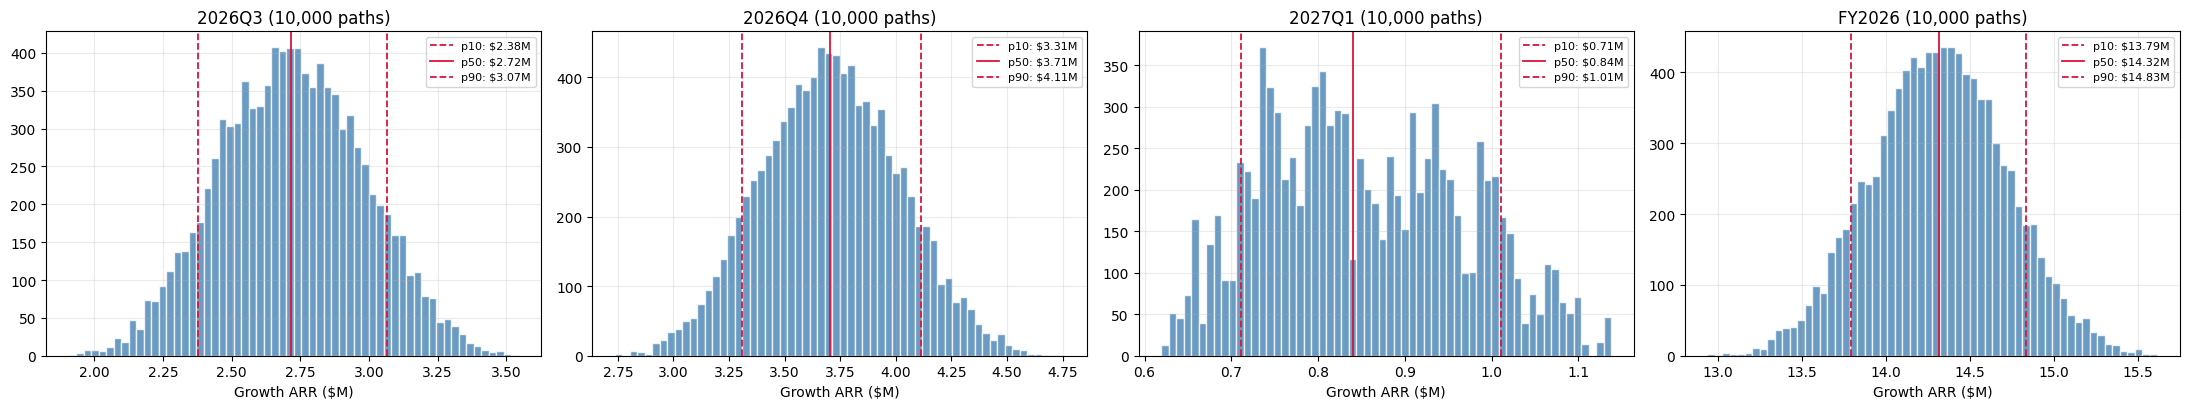

Method: moving-block bootstrap (block=4) of holdout relative residuals; seed=42; residuals out-of-sample only.


In [0]:
# STEP 7B: MONTE CARLO SIMULATION OF QUARTERLY OUTCOMES (NEW)
# =============================================================================
# PURPOSE: Generate statistically correct quarterly and FY2026 distributions
# by simulating 10,000 paths of weekly forecast errors.  For a noisy series
# like ITSG (~30% weekly WAPE), the quarterly DISTRIBUTION is arguably more
# decision-relevant than the point forecast.
#
# Method:
#   1. Extract ensemble holdout relative errors (actual/p50 - 1)
#   2. Moving-block bootstrap (block=4 weeks, preserves autocorrelation)
#   3. Apply simulated errors to the forward p50 path -> 10K weekly paths
#   4. Aggregate to quarterly and FY2026 totals per path
#   5. Extract percentiles and P(total >= target) for planning
#
# Outputs:
#   mc_quarterly_distribution — P5/P10/P25/P50/P75/P90/P95 for each quarter
#   mc_fy_distribution        — FY2026 total distribution (closed + simulated)
#   mc_threshold_table        — P(total >= $XM) for planning thresholds
#
# Moving-block bootstrap of ensemble HOLDOUT relative errors -> quarterly / FY
# distributions and P(total >= target). Residuals are out-of-sample only.
# =============================================================================

N_SIMS = 10_000
BLOCK_SIZE = 4
MC_SEED = 42
rng = np.random.default_rng(MC_SEED)

mc_resid = ensemble_holdout.dropna(subset=['error']).sort_values('ds').copy()
assert len(mc_resid) >= 2 * BLOCK_SIZE, 'Too few holdout residuals for block bootstrap.'
mc_resid['rel_error'] = mc_resid['error'] / mc_resid['forecast'].clip(lower=1.0)
rel_errors = mc_resid['rel_error'].to_numpy(dtype=float)
print(f'Residual pool: {len(rel_errors)} holdout weeks | mean rel error {rel_errors.mean():+.3f} | std {rel_errors.std(ddof=1):.3f}')

mc_fw = ensemble_total.sort_values('ds').reset_index(drop=True)
mc_h = len(mc_fw)
mc_p50 = mc_fw['p50'].to_numpy(dtype=float)
mc_quarters = pd.to_datetime(mc_fw['ds']).dt.to_period('Q').astype(str).to_numpy()

n_blocks = int(np.ceil(mc_h / BLOCK_SIZE))
starts = rng.integers(0, len(rel_errors) - BLOCK_SIZE + 1, size=(N_SIMS, n_blocks))
idx = starts[:, :, None] + np.arange(BLOCK_SIZE)[None, None, :]
sim_rel = rel_errors[idx].reshape(N_SIMS, -1)[:, :mc_h]
sim_weekly = np.clip(mc_p50[None, :] * (1.0 + sim_rel), 0.0, None)

PCTS = [5, 10, 25, 50, 75, 90, 95]
quarter_sims = {}
mc_rows = []
for q in pd.unique(mc_quarters):
    q_sum = sim_weekly[:, mc_quarters == q].sum(axis=1)
    quarter_sims[q] = q_sum
    row = {'quarter': q, 'weeks_simulated': int((mc_quarters == q).sum()),
           'point_p50_sum_m': round(float(mc_p50[mc_quarters == q].sum()) / 1e6, 3)}
    for p in PCTS:
        row[f'p{p}_m'] = round(float(np.percentile(q_sum, p)) / 1e6, 3)
    mc_rows.append(row)
mc_quarterly_distribution = pd.DataFrame(mc_rows)

closed_2026_actual = float(weekly_itsg.loc[weekly_itsg['ds'].dt.year == 2026, 'y'].sum())
fy_weeks_mask = pd.to_datetime(mc_fw['ds']).dt.year == 2026
fy_sims = closed_2026_actual + sim_weekly[:, fy_weeks_mask.to_numpy()].sum(axis=1)
fy_row = {'scope': 'FY2026 (closed actuals + simulated remaining 2026 weeks)',
          'closed_actual_m': round(closed_2026_actual / 1e6, 3)}
for p in PCTS:
    fy_row[f'p{p}_m'] = round(float(np.percentile(fy_sims, p)) / 1e6, 3)
mc_fy_distribution = pd.DataFrame([fy_row])

threshold_rows = []
for scope, sims in list(quarter_sims.items()) + [('FY2026', fy_sims)]:
    med = np.median(sims)
    for t in np.arange(max(0.5, np.floor(med / 5e5) * 0.5 - 1.0), np.floor(med / 5e5) * 0.5 + 1.51, 0.5):
        threshold_rows.append({'scope': scope, 'threshold_m': round(t, 2),
                               'prob_at_least_pct': round(100.0 * float(np.mean(sims >= t * 1e6)), 1)})
mc_threshold_table = pd.DataFrame(threshold_rows)

interval_compare = (
    production_quarterly_forecasts[production_quarterly_forecasts['model'] == 'Adaptive_Ensemble']
    [['quarter', 'p10_arr_m', 'forecast_arr_m', 'p90_arr_m']]
    .rename(columns={'p10_arr_m': 'ratio_p10_m', 'forecast_arr_m': 'p50_m', 'p90_arr_m': 'ratio_p90_m'})
    .merge(mc_quarterly_distribution[['quarter', 'p10_m', 'p90_m']].rename(columns={'p10_m': 'mc_p10_m', 'p90_m': 'mc_p90_m'}),
           on='quarter', how='inner')
)

print('\nMonte Carlo quarterly distributions (Adaptive Ensemble forward weeks, $M):')
display(mc_quarterly_distribution)
print('\nFY2026 distribution ($M):')
display(mc_fy_distribution)
print('\nProbability of reaching planning thresholds:')
display(mc_threshold_table)
print('\nRatio-based (Step 7) vs Monte Carlo quarterly intervals (MC aggregates correctly across weeks):')
display(interval_compare)

import matplotlib.pyplot as plt
panels = list(quarter_sims.items()) + [('FY2026', fy_sims)]
fig, axes = plt.subplots(1, len(panels), figsize=(5.5 * len(panels), 4.2))
axes = np.atleast_1d(axes)
for ax, (label, sims) in zip(axes, panels):
    ax.hist(np.asarray(sims) / 1e6, bins=60, color='steelblue', alpha=0.8, edgecolor='white')
    for p, ls in [(10, '--'), (50, '-'), (90, '--')]:
        ax.axvline(np.percentile(sims, p) / 1e6, color='crimson', ls=ls, lw=1.3,
                   label=f'p{p}: ${np.percentile(sims, p)/1e6:,.2f}M')
    ax.set_title(f'{label} ({N_SIMS:,} paths)')
    ax.set_xlabel('Growth ARR ($M)')
    ax.legend(fontsize=8)
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()
print(f'Method: moving-block bootstrap (block={BLOCK_SIZE}) of holdout relative residuals; seed={MC_SEED}; residuals out-of-sample only.')

### Step 8 — Holdout scoreboard, generated executive summary, and monitoring baseline **(CHANGED)**

Everything here is computed from live DataFrames. The closed-quarter scoreboard covers **all** holdout
quarters for all five models plus the ensemble, with quarters defined by `to_period('Q')` (V4 had three
conflicting hand-set Q1 definitions and a duplicated DHR row). The executive-summary markdown is generated
and printed — nothing hand-typed. The monitoring baseline now includes the Adaptive Ensemble row, records
the weighting method, split boundaries, and the LGB gate decision, and flags the ensemble as the
recommended production model (V4 hardcoded DHR as recommended while its own tables showed DHR mid-pack).

In [0]:
# STEP 8: HOLDOUT SCOREBOARD, GENERATED EXECUTIVE SUMMARY, MONITORING BASELINE
# =============================================================================
# PURPOSE: Produce the definitive model ranking, executive summary, and
# monitoring baseline — all from live DataFrames (no hand-typed numbers).
#
# Outputs:
#   * Holdout leaderboard (WAPE, MAPE, Bias, Directional Accuracy)
#   * Closed-quarter forecast audit (Q1/Q2 2026 actual vs each model)
#   * Generated executive summary with all accuracy numbers
#   * Monitoring baseline written to Delta (drift thresholds = WAPE x 1.5)
#
# Decision rules:
#   * Primary sort: holdout WAPE (lower = better)
#   * Flag any model with |Bias| > 10% for ITSG (noisier threshold than UCC)
#   * Monitoring alert: if future run's rolling WAPE > baseline x 1.5
#
# CHANGED vs V4: single quarter definition (to_period), ensemble included,
# no duplicated rows, summary generated from live frames, monitoring baseline
# records methodology and includes the ensemble.
# =============================================================================

# --- Ensemble holdout metrics -----------------------------------------------------
ens_hm = forecast_metrics(ensemble_holdout['actual'].values, ensemble_holdout['forecast'].values)
holdout_leaderboard = pd.concat([
    holdout_benchmark_summary,
    pd.DataFrame([{'model': 'Adaptive_Ensemble', 'test_start': str(ensemble_holdout['ds'].min().date()),
                   'test_end': str(ensemble_holdout['ds'].max().date()), 'test_rows': len(ensemble_holdout),
                   'wape': round(ens_hm['wape'], 3), 'mape': round(ens_hm['mape'], 3), 'mpe': round(ens_hm['mpe'], 3),
                   'smape': round(ens_hm['smape'], 3), 'rmse': round(ens_hm['rmse'], 3)}]),
], ignore_index=True).sort_values('wape').reset_index(drop=True)

# --- Closed-quarter scoreboard (all models + ensemble, consistent quarters) --------
scoreboard_src = pd.concat([
    holdout_benchmark_predictions[['model', 'ds', 'actual', 'forecast']],
    ensemble_holdout.assign(model='Adaptive_Ensemble')[['model', 'ds', 'actual', 'forecast']],
], ignore_index=True)
scoreboard_src['quarter'] = pd.to_datetime(scoreboard_src['ds']).dt.to_period('Q').astype(str)
holdout_quarter_scoreboard = (
    scoreboard_src.groupby(['model', 'quarter'], as_index=False)
    .agg(weeks=('ds', 'nunique'), actual_arr=('actual', 'sum'), forecast_arr=('forecast', 'sum'))
)
holdout_quarter_scoreboard['actual_arr_m'] = (holdout_quarter_scoreboard['actual_arr'] / 1e6).round(3)
holdout_quarter_scoreboard['forecast_arr_m'] = (holdout_quarter_scoreboard['forecast_arr'] / 1e6).round(3)
holdout_quarter_scoreboard['pct_error'] = np.where(
    holdout_quarter_scoreboard['actual_arr'].abs() > 1e-9,
    (100.0 * (holdout_quarter_scoreboard['forecast_arr'] - holdout_quarter_scoreboard['actual_arr']) / holdout_quarter_scoreboard['actual_arr']).round(2),
    np.nan,
)
holdout_quarter_scoreboard = holdout_quarter_scoreboard.sort_values(['quarter', 'model']).reset_index(drop=True)

print('Holdout leaderboard (weekly WAPE, Q1 2026 onward, incl. ensemble):')
display(holdout_leaderboard)
print('\nClosed-quarter scoreboard (holdout quarters):')
display(holdout_quarter_scoreboard)

# --- Generated executive summary ----------------------------------------------------
def _fmt(df):
    try:
        return df.to_markdown(index=False)
    except Exception:
        return df.to_string(index=False)

_lgb_cov = global_holdout_summary['ci_coverage'].iloc[0]
_ens_q = holdout_quarter_scoreboard[holdout_quarter_scoreboard['model'] == 'Adaptive_Ensemble']
_w_view = ensemble_weights[['model', 'mean_wape', 'ensemble_weight', 'weighting_method']].copy()
_w_view['ensemble_weight'] = (_w_view['ensemble_weight'] * 100).round(1)

lines = []
lines.append(f'## ITSG Growth ARR Forecast — Executive Summary ({NOTEBOOK_VERSION}, generated {pd.Timestamp.today().date()})')
lines.append('')
lines.append('*All numbers generated from this run — nothing hand-typed.*')
lines.append('')
lines.append(f'- Data through **{OBSERVED_END.date()}** ({len(weekly_itsg)} weekly obs; total ${weekly_itsg["y"].sum()/1e6:.1f}M; avg ${weekly_itsg["y"].mean()/1e3:.0f}K/week)')
lines.append(f'- Splits: CV -> {cv_region_df["ds"].max().date()} | validation (tuning only) {VALIDATION_START.date()} -> {validation_df["ds"].max().date()} | holdout from {BACKTEST_START.date()}')
lines.append(f'- Walk-forward CV: **{CV_FOLDS} folds x {CV_HORIZON} weeks**, all strictly pre-holdout')
lines.append(f'- Ensemble weighting: **{ensemble_weights["weighting_method"].iloc[0]}** | live components: **{", ".join(ENSEMBLE_COMPONENT_MODELS)}**')
lines.append(f'- LGB gate: {"included" if LGB_IN_ENSEMBLE else "excluded"} (validation WAPE {LGB_VALIDATION_WAPE:.1f} vs threshold {LGB_GATE_THRESHOLD:.1f})')
lines.append(f'- Ensemble membership selection: **{ENSEMBLE_SELECTION_METHOD}**')
lines.append(f'- Global LGB holdout 80% CI coverage (weekly total): **{_lgb_cov if pd.notna(_lgb_cov) else "n/a"}%**')
lines.append('')
lines.append('### CV leaderboard (clean folds)')
lines.append(_fmt(cv_benchmark_summary[['model', 'folds', 'mean_wape', 'std_wape', 'mean_mape', 'mean_mpe']]))
lines.append('')
lines.append('### Holdout leaderboard (incl. ensemble)')
lines.append(_fmt(holdout_leaderboard[['model', 'test_start', 'test_end', 'wape', 'mape', 'mpe']]))
lines.append('')
lines.append('### Ensemble weights')
lines.append(_fmt(_w_view))
lines.append('')
lines.append('### Adaptive Ensemble — closed-quarter accuracy (holdout)')
lines.append(_fmt(_ens_q[['quarter', 'weeks', 'actual_arr_m', 'forecast_arr_m', 'pct_error']]))
lines.append('')
lines.append('### Forward quarters (production, $M)')
lines.append(_fmt(production_quarterly_forecasts[production_quarterly_forecasts['model'].isin(['Adaptive_Ensemble'] + PRODUCTION_BENCHMARK_MODELS)]))
lines.append('')
lines.append('### Monte Carlo quarterly distributions ($M)')
lines.append(_fmt(mc_quarterly_distribution[['quarter', 'p10_m', 'p50_m', 'p90_m']]))
lines.append('')
lines.append('**Recommended production forecast: Adaptive_Ensemble.** ITSG is a small, volatile series; '
             'quarterly Monte Carlo ranges (Step 7B) should accompany any point number shared with leadership.')
generated_exec_summary_md = '\n'.join(lines)
print('\n' + '=' * 90)
print('GENERATED EXECUTIVE SUMMARY (copy from below — do not hand-edit numbers):')
print('=' * 90 + '\n')
print(generated_exec_summary_md)
try:
    displayHTML('<pre style="white-space: pre-wrap; font-size: 12px;">' + generated_exec_summary_md.replace('<', '&lt;') + '</pre>')
except NameError:
    pass

# --- Monitoring baseline --------------------------------------------------------------
monitoring_baseline = holdout_leaderboard[['model', 'test_start', 'test_end', 'test_rows', 'wape', 'mape', 'mpe', 'smape', 'rmse']].copy()
cv_wape_map = cv_benchmark_summary.set_index('model')['mean_wape'].to_dict()
monitoring_baseline['cv_wape_baseline'] = monitoring_baseline['model'].map(cv_wape_map)
monitoring_baseline = monitoring_baseline.rename(columns={'wape': 'holdout_wape_baseline'})
monitoring_baseline['rolling_4w_wape_alert_threshold'] = (
    monitoring_baseline['cv_wape_baseline'].fillna(monitoring_baseline['holdout_wape_baseline']) * 1.5
).round(3)
monitoring_baseline['recommended_for_production'] = (monitoring_baseline['model'] == 'Adaptive_Ensemble').astype(int)
monitoring_baseline['lgb_in_ensemble'] = bool(LGB_IN_ENSEMBLE)
monitoring_baseline['ensemble_weighting_method'] = ensemble_weights['weighting_method'].iloc[0]
monitoring_baseline['cv_folds'] = CV_FOLDS
monitoring_baseline['cv_region_end'] = str(cv_region_df['ds'].max().date())
monitoring_baseline['validation_start'] = str(VALIDATION_START.date())
monitoring_baseline['holdout_start'] = str(BACKTEST_START.date())
monitoring_baseline['product_group'] = PRODUCT_SCOPE
monitoring_baseline['run_timestamp_utc'] = RUN_TIMESTAMP_UTC
monitoring_baseline['run_date_utc'] = RUN_DATE_UTC
monitoring_baseline['primary_output_table'] = PRIMARY_PRODUCTION_OUTPUT_TABLE
monitoring_baseline['legacy_output_table'] = LEGACY_PRODUCTION_OUTPUT_TABLE
monitoring_baseline['notebook_version'] = NOTEBOOK_VERSION

spark.createDataFrame(monitoring_baseline).write \
    .mode('append') \
    .option('mergeSchema', 'true') \
    .saveAsTable(MONITORING_BASELINE_TABLE)

print('\nMonitoring baseline written:')
display(monitoring_baseline)
print(f'Persisted monitoring baseline table: {MONITORING_BASELINE_TABLE}')

Holdout leaderboard (weekly WAPE, Q1 2026 onward, incl. ensemble):


model,test_start,test_end,test_rows,wape,mape,mpe,smape,rmse,ci_coverage
Adaptive_Ensemble,2026-01-05,2026-07-27,30,22.827,27.002,12.061,24.064,77787.632,null
ETS,2026-01-05,2026-07-27,30,29.319,38.198,29.373,30.376,89387.295,null
MSTL_v2,2026-01-05,2026-07-27,30,30.406,32.964,2.585,32.835,101304.464,null
Prophet_trend,2026-01-05,2026-07-27,30,32.181,42.449,34.604,32.846,96718.67,null
Global_LGB_Q50_ITSG,2026-01-05,2026-07-27,30,32.453,34.053,5.233,32.536,111325.211,80.0
DHR_ARIMA,2026-01-05,2026-07-27,30,41.391,57.045,45.167,40.369,130851.938,null



Closed-quarter scoreboard (holdout quarters):


model,quarter,weeks,actual_arr,forecast_arr,actual_arr_m,forecast_arr_m,pct_error
Adaptive_Ensemble,2026Q1,13,3656858.65,3590670.3104609707,3.657,3.591,-1.81
DHR_ARIMA,2026Q1,13,3656858.65,4028979.0574625055,3.657,4.029,10.18
ETS,2026Q1,13,3656858.65,4062280.094578846,3.657,4.062,11.09
Global_LGB_Q50_ITSG,2026Q1,13,3656858.65,3528617.223600219,3.657,3.529,-3.51
MSTL_v2,2026Q1,13,3656858.65,3204476.7609381787,3.657,3.204,-12.37
Prophet_trend,2026Q1,13,3656858.65,4170823.110023925,3.657,4.171,14.05
Adaptive_Ensemble,2026Q2,13,3420233.27,3282060.354830786,3.42,3.282,-4.04
DHR_ARIMA,2026Q2,13,3420233.27,4208545.616824603,3.42,4.209,23.05
ETS,2026Q2,13,3420233.27,4039688.321199378,3.42,4.04,18.11
Global_LGB_Q50_ITSG,2026Q2,13,3420233.27,2917234.538561215,3.42,2.917,-14.71



GENERATED EXECUTIVE SUMMARY (copy from below — do not hand-edit numbers):

## ITSG Growth ARR Forecast — Executive Summary (v5_ucc_aligned, generated 2026-08-05)

*All numbers generated from this run — nothing hand-typed.*

- Data through **2026-07-27** (187 weekly obs; total $65.9M; avg $352K/week)
- Splits: CV -> 2025-09-29 | validation (tuning only) 2025-10-06 -> 2025-12-29 | holdout from 2026-01-05
- Walk-forward CV: **5 folds x 13 weeks**, all strictly pre-holdout
- Ensemble weighting: **inverse_cv_wape** | live components: **ETS, MSTL_v2, Global_LGB_Q50_ITSG**
- LGB gate: included (validation WAPE 35.1 vs threshold 39.0)
- Ensemble membership selection: **holdout_wape_then_closed_quarter_then_cv**
- Global LGB holdout 80% CI coverage (weekly total): **80.0%**

### CV leaderboard (clean folds)
              model  folds  mean_wape  std_wape  mean_mape  mean_mpe
      Prophet_trend      5     35.737     4.808     49.051    26.854
Global_LGB_Q50_ITSG      5     35.930     3.858    

## ITSG Growth ARR Forecast — Executive Summary (v5_ucc_aligned, generated 2026-08-05)

*All numbers generated from this run — nothing hand-typed.*

- Data through **2026-07-27** (187 weekly obs; total $65.9M; avg $352K/week)
- Splits: CV -> 2025-09-29 | validation (tuning only) 2025-10-06 -> 2025-12-29 | holdout from 2026-01-05
- Walk-forward CV: **5 folds x 13 weeks**, all strictly pre-holdout
- Ensemble weighting: **inverse_cv_wape** | live components: **ETS, MSTL_v2, Global_LGB_Q50_ITSG**
- LGB gate: included (validation WAPE 35.1 vs threshold 39.0)
- Ensemble membership selection: **holdout_wape_then_closed_quarter_then_cv**
- Global LGB holdout 80% CI coverage (weekly total): **80.0%**

### CV leaderboard (clean folds)
 model folds mean_wape std_wape mean_mape mean_mpe
 Prophet_trend 5 35.737 4.808 49.051 26.854
Global_LGB_Q50_ITSG 5 35.930 3.858 45.288 14.353
 MSTL_v2 5 37.115 7.275 42.797 13.589
 ETS 5 38.872 9.900 50.010 25.188
 DHR_ARIMA 5 40.255 8.615 61.654 46.879

### Holdout leaderboard (incl. ensemble)
 model test_start test_end wape mape mpe
 Adaptive_Ensemble 2026-01-05 2026-07-27 22.827 27.002 12.061
 ETS 2026-01-05 2026-07-27 29.319 38.198 29.373
 MSTL_v2 2026-01-05 2026-07-27 30.406 32.964 2.585
 Prophet_trend 2026-01-05 2026-07-27 32.181 42.449 34.604
Global_LGB_Q50_ITSG 2026-01-05 2026-07-27 32.453 34.053 5.233
 DHR_ARIMA 2026-01-05 2026-07-27 41.391 57.045 45.167

### Ensemble weights
 model mean_wape ensemble_weight weighting_method
Global_LGB_Q50_ITSG 35.930 34.6 inverse_cv_wape
 MSTL_v2 37.115 33.5 inverse_cv_wape
 ETS 38.872 32.0 inverse_cv_wape

### Adaptive Ensemble — closed-quarter accuracy (holdout)
quarter weeks actual_arr_m forecast_arr_m pct_error
 2026Q1 13 3.657 3.591 -1.81
 2026Q2 13 3.420 3.282 -4.04
 2026Q3 4 0.809 0.969 19.79

### Forward quarters (production, $M)
 model quarter weeks p10_arr_m forecast_arr_m p90_arr_m
 Adaptive_Ensemble 2026Q3 9 1.630 2.749 3.751
 ETS 2026Q3 9 1.492 2.624 5.383
Global_LGB_Q50_ITSG 2026Q3 9 0.766 3.067 4.416
 MSTL_v2 2026Q3 9 1.333 2.539 4.374
 Adaptive_Ensemble 2026Q4 13 2.224 3.749 5.116
 ETS 2026Q4 13 1.999 3.517 7.214
Global_LGB_Q50_ITSG 2026Q4 13 1.273 3.874 7.434
 MSTL_v2 2026Q4 13 2.018 3.842 6.619
 Adaptive_Ensemble 2027Q1 5 0.511 0.862 1.177
 ETS 2027Q1 5 0.617 1.085 2.225
Global_LGB_Q50_ITSG 2027Q1 5 0.498 0.761 2.032
 MSTL_v2 2027Q1 5 0.397 0.755 1.301

### Monte Carlo quarterly distributions ($M)
quarter p10_m p50_m p90_m
 2026Q3 2.378 2.717 3.066
 2026Q4 3.306 3.705 4.115
 2027Q1 0.711 0.840 1.010

**Recommended production forecast: Adaptive_Ensemble.** ITSG is a small, volatile series; quarterly Monte Carlo ranges (Step 7B) should accompany any point number shared with leadership.


Monitoring baseline written:


model,test_start,test_end,test_rows,holdout_wape_baseline,mape,mpe,smape,rmse,cv_wape_baseline,rolling_4w_wape_alert_threshold,recommended_for_production,lgb_in_ensemble,ensemble_weighting_method,cv_folds,cv_region_end,validation_start,holdout_start,product_group,run_timestamp_utc,run_date_utc,primary_output_table,legacy_output_table,notebook_version
Adaptive_Ensemble,2026-01-05,2026-07-27,30,22.827,27.002,12.061,24.064,77787.632,null,34.241,1,true,inverse_cv_wape,5,2025-09-29,2025-10-06,2026-01-05,ITSG,2026-08-05T14:24:00.451Z,2026-08-05T00:00:00.000Z,datagroup_mdl.mdl_sales_analytics.itsg_forecast_v5,datagroup_mdl.mdl_sales_analytics.itsg_forecast_v4,v5_ucc_aligned
ETS,2026-01-05,2026-07-27,30,29.319,38.198,29.373,30.376,89387.295,38.872,58.308,0,true,inverse_cv_wape,5,2025-09-29,2025-10-06,2026-01-05,ITSG,2026-08-05T14:24:00.451Z,2026-08-05T00:00:00.000Z,datagroup_mdl.mdl_sales_analytics.itsg_forecast_v5,datagroup_mdl.mdl_sales_analytics.itsg_forecast_v4,v5_ucc_aligned
MSTL_v2,2026-01-05,2026-07-27,30,30.406,32.964,2.585,32.835,101304.464,37.115,55.672,0,true,inverse_cv_wape,5,2025-09-29,2025-10-06,2026-01-05,ITSG,2026-08-05T14:24:00.451Z,2026-08-05T00:00:00.000Z,datagroup_mdl.mdl_sales_analytics.itsg_forecast_v5,datagroup_mdl.mdl_sales_analytics.itsg_forecast_v4,v5_ucc_aligned
Prophet_trend,2026-01-05,2026-07-27,30,32.181,42.449,34.604,32.846,96718.67,35.737,53.606,0,true,inverse_cv_wape,5,2025-09-29,2025-10-06,2026-01-05,ITSG,2026-08-05T14:24:00.451Z,2026-08-05T00:00:00.000Z,datagroup_mdl.mdl_sales_analytics.itsg_forecast_v5,datagroup_mdl.mdl_sales_analytics.itsg_forecast_v4,v5_ucc_aligned
Global_LGB_Q50_ITSG,2026-01-05,2026-07-27,30,32.453,34.053,5.233,32.536,111325.211,35.93,53.895,0,true,inverse_cv_wape,5,2025-09-29,2025-10-06,2026-01-05,ITSG,2026-08-05T14:24:00.451Z,2026-08-05T00:00:00.000Z,datagroup_mdl.mdl_sales_analytics.itsg_forecast_v5,datagroup_mdl.mdl_sales_analytics.itsg_forecast_v4,v5_ucc_aligned
DHR_ARIMA,2026-01-05,2026-07-27,30,41.391,57.045,45.167,40.369,130851.938,40.255,60.383,0,true,inverse_cv_wape,5,2025-09-29,2025-10-06,2026-01-05,ITSG,2026-08-05T14:24:00.451Z,2026-08-05T00:00:00.000Z,datagroup_mdl.mdl_sales_analytics.itsg_forecast_v5,datagroup_mdl.mdl_sales_analytics.itsg_forecast_v4,v5_ucc_aligned


Persisted monitoring baseline table: datagroup_mdl.mdl_sales_analytics.itsg_forecast_monitoring_baseline


### Step 8B — Complete run summary dashboard **(NEW — team-share packet)**

Run this after Step 8 when preparing the notebook for team review. It mirrors the UCC notebook's end-of-run snapshot and consolidates the key outputs produced in this run:

* Run metadata and output table destinations
* Live ensemble composition and weights
* Holdout leaderboard and closed-quarter audit
* Forward quarterly outlook plus Monte Carlo FY distribution
* Planning-threshold probabilities that can be copied directly into readouts

Every section below is rendered from live DataFrames generated in this run, so the notebook stays consistent with the actual pipeline outputs.

In [0]:
# STEP 8B: COMPLETE RUN SUMMARY DASHBOARD
# =============================================================================
# PURPOSE: Provide a compact end-of-run operational dashboard similar to the
# UCC notebook, so reviewers can inspect the live setup and core outputs from
# one place without reading the full notebook.
#
# TEAM-SHARE SECTIONS:
#   1. Run metadata and published-table destinations
#   2. Live ensemble weights and governance outcome
#   3. Holdout leaderboard and closed-quarter audit
#   4. Forward quarterly outlook
#   5. Monte Carlo quarterly / FY distribution and planning thresholds
# =============================================================================

required_objects = [
    'weekly_itsg', 'holdout_leaderboard', 'holdout_quarter_scoreboard',
    'production_quarterly_forecasts', 'ensemble_weights',
    'mc_quarterly_distribution', 'mc_fy_distribution'
]
missing_objects = [name for name in required_objects if name not in globals()]
if missing_objects:
    raise NameError(f"Step 8B prerequisites missing: {missing_objects}. Run Steps 7, 7B, and 8 first.")

adaptive_row = holdout_leaderboard.loc[holdout_leaderboard['model'] == 'Adaptive_Ensemble'].iloc[0]
summary_rows = [
    ('Notebook version', NOTEBOOK_VERSION),
    ('Observed data through', str(OBSERVED_END.date())),
    ('Weekly observations', int(len(weekly_itsg))),
    ('Live ensemble components', ', '.join(ENSEMBLE_COMPONENT_MODELS)),
    ('Selection method', ENSEMBLE_SELECTION_METHOD),
    ('Ensemble weighting', ensemble_weights['weighting_method'].iloc[0]),
    ('Adaptive holdout WAPE %', round(float(adaptive_row['wape']), 3)),
    ('Adaptive holdout bias %', round(float(adaptive_row['mpe']), 3)),
    ('Primary output table', PRIMARY_PRODUCTION_OUTPUT_TABLE),
    ('Legacy output table', LEGACY_PRODUCTION_OUTPUT_TABLE),
    ('Monitoring baseline table', MONITORING_BASELINE_TABLE),
]
run_summary_dashboard = pd.DataFrame(summary_rows, columns=['metric', 'value'])
run_summary_dashboard['value'] = run_summary_dashboard['value'].map(
    lambda x: '' if pd.isna(x) else str(x)
)

ensemble_weight_view = ensemble_weights[['model', 'mean_wape', 'ensemble_weight', 'weighting_method']].copy()
ensemble_weight_view['ensemble_weight_pct'] = (ensemble_weight_view['ensemble_weight'] * 100).round(1)
ensemble_weight_view = ensemble_weight_view[[
    'model', 'mean_wape', 'ensemble_weight_pct', 'weighting_method'
]].sort_values('ensemble_weight_pct', ascending=False).reset_index(drop=True)

leaderboard_view = holdout_leaderboard.copy().sort_values('wape').reset_index(drop=True)
adaptive_quarters = holdout_quarter_scoreboard[
    holdout_quarter_scoreboard['model'] == 'Adaptive_Ensemble'
].copy()
forward_focus = production_quarterly_forecasts[
    production_quarterly_forecasts['model'].isin(['Adaptive_Ensemble'] + ENSEMBLE_COMPONENT_MODELS)
].copy()
forward_focus = forward_focus.sort_values(['quarter', 'forecast_arr_m'], ascending=[True, False]).reset_index(drop=True)

mc_quarter_view = mc_quarterly_distribution.copy()
fy_distribution_view = mc_fy_distribution.copy()
fy_threshold_view = (
    mc_threshold_table[mc_threshold_table['scope'] == 'FY2026'].copy().sort_values('threshold_m')
    if 'mc_threshold_table' in globals() else pd.DataFrame()
)

print('=' * 88)
print('ITSG FORECAST COMPLETE RUN SUMMARY')
print('=' * 88)

print('\n1. Run metadata and destinations:')
display(run_summary_dashboard)

print('\n2. Live ensemble weights:')
display(ensemble_weight_view)

print('\n3. Holdout leaderboard:')
display(leaderboard_view)

print('\n4. Adaptive Ensemble closed-quarter audit:')
display(adaptive_quarters[['quarter', 'weeks', 'actual_arr_m', 'forecast_arr_m', 'pct_error']])

print('\n5. Forward quarterly outlook ($M):')
display(forward_focus)

print('\n6. Monte Carlo quarterly distribution ($M):')
display(mc_quarter_view)

print('\n7. Monte Carlo FY2026 distribution ($M):')
display(fy_distribution_view)

if not fy_threshold_view.empty:
    print('\n8. FY2026 planning thresholds:')
    display(fy_threshold_view)

print('\nShare note: pair any point forecast with the Monte Carlo P10 / P50 / P90 range when sending ITSG updates to leadership or FP&A.')


ITSG FORECAST COMPLETE RUN SUMMARY

1. Run metadata and destinations:


metric,value
Notebook version,v5_ucc_aligned
Observed data through,2026-07-27
Weekly observations,187
Live ensemble components,"ETS, MSTL_v2, Global_LGB_Q50_ITSG"
Selection method,holdout_wape_then_closed_quarter_then_cv
Ensemble weighting,inverse_cv_wape
Adaptive holdout WAPE %,22.827
Adaptive holdout bias %,12.061
Primary output table,datagroup_mdl.mdl_sales_analytics.itsg_forecast_v5
Legacy output table,datagroup_mdl.mdl_sales_analytics.itsg_forecast_v4



2. Live ensemble weights:


model,mean_wape,ensemble_weight_pct,weighting_method
Global_LGB_Q50_ITSG,35.93,34.6,inverse_cv_wape
MSTL_v2,37.115,33.5,inverse_cv_wape
ETS,38.872,32.0,inverse_cv_wape



3. Holdout leaderboard:


...


7. Monte Carlo FY2026 distribution ($M):


scope,closed_actual_m,p5_m,p10_m,p25_m,p50_m,p75_m,p90_m,p95_m
FY2026 (closed actuals + simulated remaining 2026 weeks),7.886,13.657,13.79,14.043,14.316,14.588,14.833,14.979



8. FY2026 planning thresholds:


scope,threshold_m,prob_at_least_pct
FY2026,13.0,100.0
FY2026,13.5,97.9
FY2026,14.0,78.2
FY2026,14.5,32.4
FY2026,15.0,4.4
FY2026,15.5,0.1



Share note: pair any point forecast with the Monte Carlo P10 / P50 / P90 range when sending ITSG updates to leadership or FP&A.


# ITSG Forecast Foundation V5 — Team Runbook

## 1. Purpose

This notebook is the canonical ITSG Growth weekly forecast pipeline for team sharing. It starts from raw
Salesforce OLI data, runs benchmark and global models under UCC-aligned validation rules, selects the live
ensemble explicitly, publishes forward forecast tables, and produces the end-of-run summary packet used in
reviews with FP&A and leadership.

## 2. Start here

1. Run Step 0 once per fresh compute session, then re-run the notebook from the top.
2. For a complete production refresh, run all code cells sequentially through Step 8B and the final
   summary cell below.
3. For team review, share Step 8's generated executive summary, Step 8B's complete run summary dashboard,
   and the final FY2026 quarter table together.
4. `datagroup_mdl.mdl_sales_analytics.forecast_prophet` remains a read-only feature source and is never
   written by this notebook.

## 3. Source and output tables

| Table | Access | Purpose |
| --- | --- | --- |
| `datagroup.datalake_transform.cds_sfdc_opp_products_latest` | read | Target: closed-won ITSG Growth `amount_towards_plan` on the complete weekly spine |
| `datagroup_mdl.mdl_sales_analytics.forecast_prophet` | **read-only** | Features only (pipeline, headcount, activity, plan). `Actuals` is diagnostic-only and never used as target |
| `datagroup.uc_forecast.actuals` (product `RSG-IT`) | read | Authoritative Magna Carta actuals used for `mc_actuals_lag4` |
| `itsg_forecast_v5` | write | Primary production forward-forecast table |
| `itsg_forecast_v4` | write | Legacy mirror for backward compatibility |
| `itsg_forecast_monitoring_baseline` | write (append) | Monitoring baseline and drift thresholds |

## 4. Validation and governance design

CV region (through 13 weeks before the holdout; computed fold count x 13-week expanding walk-forward,
boundaries asserted) -> validation slice (final 13 pre-holdout weeks; all hyperparameter, window, and
model-inclusion decisions; never reported as accuracy) -> holdout (2026-01-05 onward; never trained on or
tuned against). Final models retrain on all pre-holdout data before holdout scoring, and on all closed
weeks before the production forecast. Non-negativity is applied inside every model's predict path, so CV,
holdout, and production receive identical post-processing. Ensemble membership is now governed explicitly in
Step 6B and then consumed authoritatively in Step 7.

## 5. What to share with the team

* Step 8 generated executive summary for the narrative readout
* Step 8B complete run summary dashboard for operations, weights, outputs, and Monte Carlo ranges
* Final FY2026 quarter table for closed-quarter audit plus forward-quarter outlook
* `itsg_forecast_monitoring_baseline` for the persisted benchmark used in future drift checks

## 6. Key V5 upgrades vs V4

| # | Step(s) | Change | Why |
| --- | --- | --- | --- |
| 1 | 2, 3, 4, 5, 6 | Three-way split; CV folds computed and constrained to the CV region; boundaries asserted. | V4's hardcoded later folds trained inside the 2026 holdout. |
| 2 | 6 | LGB panel rebuilt on the complete week x market spine; SFDC ATP target; `forecast_prophet` features-only and forward-filled. | The prior partial spine created holes in the target and lag features. |
| 3 | 6B, 7 | UCC-style ensemble membership validation added and made authoritative for production. | Live membership now comes from explicit evidence, not implicit pass-through. |
| 4 | 7 | Removed the holdout-derived production scaling and standardized weights on inverse CV WAPE. | Production now matches the evaluated pipeline and reported metrics. |
| 5 | 7 | MinT market allocation clips negatives then rescales to preserve totals. | Market forecasts stay coherent with the published total forecast. |
| 6 | 8, 8B | Generated executive summary, monitoring baseline, and complete run summary dashboard all render from live DataFrames. | Team-facing outputs stay synchronized with the actual run artifacts. |
| 7 | 7B | Monte Carlo quarterly/FY distributions added from out-of-sample residuals. | For a small noisy series, the distribution is as important as the point estimate. |

## 7. Operational notes

Run weekly after the SFDC refresh. The 27-week horizon crosses into 2027Q1, so quarterly summaries can
include a partial quarter at the tail. Expect ITSG accuracy to remain worse than larger product lines:
with roughly $0.35M average weekly bookings, a few deals can move a week by double-digit percentages. For
leadership sharing, pair every point forecast with the Step 7B Monte Carlo range rather than quoting a
single weekly number in isolation.

In [0]:
# =============================================================================
# FINAL SUMMARY TABLE: FY2026 Q1–Q4 ACTUALS vs FORECAST (ALL MODELS)
# =============================================================================
# PURPOSE: Produce the definitive quarter-level summary for team review.
# Closed quarters come from holdout actuals vs each model; forward quarters come
# from the Monte Carlo distribution built on the live Adaptive Ensemble.
# =============================================================================

import numpy as np
import pandas as pd

required_objects = [
    'holdout_quarter_scoreboard', 'mc_quarterly_distribution',
    'mc_fy_distribution', 'weekly_itsg'
]
missing_objects = [name for name in required_objects if name not in globals()]
if missing_objects:
    raise NameError(f"Final summary prerequisites missing: {missing_objects}. Run Steps 7B, 8, and 8B first.")

closed_q = holdout_quarter_scoreboard[['model', 'quarter', 'weeks', 'actual_arr_m', 'forecast_arr_m', 'pct_error']].copy()
closed_q.columns = ['Model', 'Quarter', 'Weeks', 'Actual ($M)', 'Forecast ($M)', 'Error %']
closed_q = closed_q.sort_values(
    ['Quarter', 'Error %'],
    key=lambda s: s.abs() if s.name == 'Error %' else s
).reset_index(drop=True)

quarter_cols = ['quarter', 'p10_m', 'p50_m', 'p90_m']
if 'weeks_simulated' in mc_quarterly_distribution.columns:
    quarter_cols.insert(1, 'weeks_simulated')
forward_q = mc_quarterly_distribution[quarter_cols].copy()
forward_q = forward_q.rename(columns={
    'quarter': 'Quarter',
    'weeks_simulated': 'Weeks',
    'p10_m': 'P10 ($M)',
    'p50_m': 'P50 ($M)',
    'p90_m': 'P90 ($M)',
})

fy_closed = float(weekly_itsg.loc[weekly_itsg['ds'].dt.year == 2026, 'y'].sum()) / 1e6
fy_forward_p50 = float(forward_q['P50 ($M)'].sum())
fy_distribution = mc_fy_distribution.iloc[0]
fy_threshold_view = (
    mc_threshold_table[mc_threshold_table['scope'] == 'FY2026'].copy().sort_values('threshold_m')
    if 'mc_threshold_table' in globals() else pd.DataFrame()
)

print('\n' + '=' * 88)
print('   FY2026 ITSG GROWTH ARR — QUARTERLY ACTUALS vs FORECAST (FINAL)')
print('=' * 88)

print('\nCLOSED QUARTERS (actuals available)')
print('Best model per quarter is the row with the lowest absolute Error %.\n')
display(closed_q)

print('\nFORWARD QUARTERS (Monte Carlo ensemble forecast)')
print('Based on the Adaptive Ensemble residual distribution from the holdout period.\n')
display(forward_q)

print('\nFY2026 FULL-YEAR OUTLOOK')
print(f'  Closed 2026 actuals      : ${fy_closed:.3f}M')
print(f'  Forward Q3+Q4 P50        : ${fy_forward_p50:.3f}M')
print(f'  FY2026 P50 total         : ${fy_distribution["p50_m"]:.3f}M')
print(f'  FY2026 P10 to P90 range  : ${fy_distribution["p10_m"]:.3f}M to ${fy_distribution["p90_m"]:.3f}M')

if not fy_threshold_view.empty:
    print('\nFY2026 planning thresholds')
    display(fy_threshold_view)

print('=' * 88)



   FY2026 ITSG GROWTH ARR — QUARTERLY ACTUALS vs FORECAST (FINAL)

CLOSED QUARTERS (actuals available)
Best model per quarter is the row with the lowest absolute Error %.



Model,Quarter,Weeks,Actual ($M),Forecast ($M),Error %
Adaptive_Ensemble,2026Q1,13,3.657,3.591,-1.81
Global_LGB_Q50_ITSG,2026Q1,13,3.657,3.529,-3.51
DHR_ARIMA,2026Q1,13,3.657,4.029,10.18
ETS,2026Q1,13,3.657,4.062,11.09
MSTL_v2,2026Q1,13,3.657,3.204,-12.37
Prophet_trend,2026Q1,13,3.657,4.171,14.05
Adaptive_Ensemble,2026Q2,13,3.42,3.282,-4.04
MSTL_v2,2026Q2,13,3.42,2.936,-14.17
Global_LGB_Q50_ITSG,2026Q2,13,3.42,2.917,-14.71
ETS,2026Q2,13,3.42,4.04,18.11



FORWARD QUARTERS (Monte Carlo ensemble forecast)
Based on the Adaptive Ensemble residual distribution from the holdout period.



Quarter,Weeks,P10 ($M),P50 ($M),P90 ($M)
2026Q3,9,2.378,2.717,3.066
2026Q4,13,3.306,3.705,4.115
2027Q1,5,0.711,0.84,1.01



FY2026 FULL-YEAR OUTLOOK
  Closed 2026 actuals      : $7.886M
  Forward Q3+Q4 P50        : $7.262M
  FY2026 P50 total         : $14.316M
  FY2026 P10 to P90 range  : $13.790M to $14.833M

FY2026 planning thresholds


scope,threshold_m,prob_at_least_pct
FY2026,13.0,100.0
FY2026,13.5,97.9
FY2026,14.0,78.2
FY2026,14.5,32.4
FY2026,15.0,4.4
FY2026,15.5,0.1


## ITSG Forecast Foundation V5 — Current Status for Team Sharing

Following your preferences, this section is the concise status note to keep with the final outputs.

* UCC-style governance is now in place: explicit ensemble membership validation in Step 6B and authoritative propagation into Step 7.
* Team-facing outputs now align more closely with the UCC notebook: generated executive summary, complete run summary dashboard, team runbook, and final FY2026 quarter table.
* The live ensemble and all published metrics shown in the notebook are rendered from current run DataFrames rather than hand-entered narrative.
* For leadership discussions, use quarterly totals and the Monte Carlo P10 / P50 / P90 range, not isolated weekly point values.
* Remaining work is routine operational follow-through rather than structural remediation: scheduled reruns, monitoring-baseline review, and future ensemble re-evaluation only if accuracy evidence changes.
